# Segmentation des utilisateurs d'Instagram : usage et bien-être

**Rush 4 · Bootcamp Data · livrable final**

## Objectif
**Étudier les relations entre l'utilisation d'Instagram et le bien-être des utilisateurs**, à partir d'un jeu de données de 200 000 personnes.

Le département Innovation d'Instagram nous demande de **livrer une segmentation des utilisateurs** qui :
- **repose sur leur usage** de l'application ;
- **explique le lien entre l'usage et le bien-être** ;
- est **utilisable par les équipes produit** ;
- est **défendue devant un jury**.

## Le contexte
Les réseaux sociaux doivent prouver qu'ils ne nuisent pas à leurs utilisateurs : les régulateurs posent des questions, la presse publie des études et les annonceurs ne veulent pas être associés à une plateforme qui rend les gens malheureux. Instagram veut **sa propre réponse, fondée sur ses propres données**.

- Les données de **bien-être et de santé** (stress, bonheur, sommeil…) viennent d'un **panel de volontaires** qui ont accepté une étude bien-être.
- Les données d'**usage** (temps passé, sessions, likes…) et de **profil** (âge, pays…) existent pour **tous** les utilisateurs.
- Nous travaillons sur une **réplique synthétique** du panel, fournie par l'équipe vie privée. Nos recommandations, elles, s'appliqueront à de vrais utilisateurs.

## Définitions
- **Bien-être :** l'Organisation mondiale de la santé définit la santé comme « un état de complet bien-être physique, mental et social », qui ne se réduit pas à l'absence de maladie ([constitution de l'OMS](https://www.who.int/fr/about/governance/constitution)). La santé mentale y est décrite comme un état de bien-être qui permet notamment de surmonter les tensions normales de la vie ([Santé publique France, sante.fr](https://www.sante.fr/toutes-et-tous-une-sante-mentale)). Nous mesurons le bien-être avec **deux indicateurs** : le stress et le bonheur.
- **Bonheur :** une **auto-évaluation** de sa propre vie sur une échelle, comme l'échelle de Cantril (de 0 à 10) utilisée par le [World Happiness Report](https://www.worldhappiness.report/faq/). Dans nos données, le **bonheur déclaré** (`self_reported_happiness`) va de 1 à 10.
- **Stress :** le **stress perçu** (`perceived_stress_score`) va de 0 à 40. C'est la plage de l'échelle **PSS-10**, sans que la documentation le confirme. On considère le stress comme **élevé à partir de 27**, une convention de lecture courante et non un seuil de diagnostic ([guide de cotation, NovoPsych](https://novopsych.com.au/wp-content/uploads/2022/02/pss-10-report-PDF.pdf)).
- **Plus heureux / moins heureux :** les utilisateurs au bonheur de **9 ou 10** (20 % des utilisateurs) et de **1 ou 2** (20 % des utilisateurs).

## Les règles suivies
- **Aucune donnée individuelle n'est affichée** : seulement des moyennes de groupes, et jamais un groupe de **moins de 100 utilisateurs**.
- **Résultats identiques à chaque exécution** : aucun tirage aléatoire.
- **« À temps égal »** : on compare des utilisateurs qui passent le même temps sur Instagram (par tranches de 10 minutes). C'est ce qui permet de savoir si une habitude compte **en plus** du temps passé.
- **Ce sont des corrélations**, pas des preuves de cause à effet.

## Le plan
0. Nettoyage et données
1. Les hypothèses non concluantes
2. Le temps passé sur Instagram
3. Le rôle de l'âge
4. Les habitudes d'utilisation
5. Stress et bonheur
6. La segmentation
7. Protection des données
8. Limites
9. Conclusion et recommandations

L'application Streamlit `notebook_Instagram_final.py` présente exactement les mêmes résultats, sous forme interactive.

---
## 0. Nettoyage et données

### 0.1 Bibliothèques, style des graphiques et outils

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, to_rgba
from matplotlib.ticker import FuncFormatter
from IPython.display import display

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

# Couleurs (palette vérifiée pour les daltonismes les plus courants)
SURFACE = "#fcfcfb"
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
BLEU, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
RAMPE_4 = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
CMAP_SEQ = LinearSegmentedColormap.from_list(
    "bleu", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "figure.figsize": (9, 4.6),
    "font.family": "sans-serif", "font.size": 10.5,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12.5, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "legend.frameon": False, "legend.fontsize": 9.5,
    "lines.linewidth": 2, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
})


def fr(valeur, decimales=1):
    """Écrit un nombre à la française : virgule décimale, espace pour les milliers."""
    if pd.isna(valeur):
        return "—"
    if round(valeur, decimales) == 0:
        valeur = 0.0
    return f"{valeur:,.{decimales}f}".replace(",", " ").replace(".", ",")


def afficher(table, decimales=1):
    """Affiche un tableau agrégé avec des nombres au format français."""
    def formater(v):
        if isinstance(v, (bool, np.bool_)):
            return "oui" if v else "non"
        if isinstance(v, (int, np.integer)):
            return fr(v, 0)
        if isinstance(v, (float, np.floating)):
            return fr(v, decimales)
        return v
    display(table.apply(lambda colonne: colonne.map(formater)))


def titrer(ax, titre, sous_titre=None):
    ax.set_title(titre, loc="left", pad=26 if sous_titre else 10)
    if sous_titre:
        ax.text(0, 1.02, sous_titre, transform=ax.transAxes, fontsize=9.5, color=INK2, ha="left", va="bottom")


def titrer_figure(fig, titre, sous_titre=None):
    """Titre d'une figure à plusieurs panneaux (à appeler après tight_layout)."""
    if sous_titre:
        fig.text(0.01, 1.0, sous_titre, ha="left", va="bottom", fontsize=9.5, color=INK2)
    fig.text(0.01, 1.0 + (0.28 / fig.get_figheight() if sous_titre else 0), titre, ha="left", va="bottom",
             fontsize=12.5, fontweight="semibold", color=INK)


def panneau(ax, titre):
    ax.set_title(titre, fontsize=10.5, loc="left", pad=8)


def barres(ax, valeurs, etiquettes, couleur=BLEU, decimales=1, suffixe="", rotation=0):
    """Barres verticales avec la valeur écrite au-dessus de chaque barre."""
    valeurs = np.asarray(valeurs, dtype=float)
    positions = np.arange(len(valeurs))
    ax.bar(positions, valeurs, width=0.55, color=couleur)
    for p, v in zip(positions, valeurs):
        ax.text(p, v + np.nanmax(valeurs) * 0.015, fr(v, decimales) + suffixe, ha="center", va="bottom", fontsize=9, color=INK)
    ax.set_xticks(positions, etiquettes, rotation=rotation, ha="right" if rotation else "center")
    ax.grid(axis="x", visible=False)


def barres_groupees(ax, table, couleurs, decimales=1, rotation=0):
    """Barres groupées : une ligne par groupe, une couleur par colonne du tableau."""
    n = table.shape[1]
    largeur = 0.8 / n
    x = np.arange(len(table))
    for k, (colonne, couleur) in enumerate(zip(table.columns, couleurs)):
        positions = x - 0.4 + largeur * (k + 0.5)
        ax.bar(positions, table[colonne], width=largeur * 0.9, color=couleur, label=colonne)
        for p, v in zip(positions, table[colonne]):
            ax.text(p, v + table.to_numpy().max() * 0.012, fr(v, decimales), ha="center", va="bottom", fontsize=7.8, color=INK2)
    ax.set_xticks(x, table.index, rotation=rotation, ha="right" if rotation else "center")
    ax.grid(axis="x", visible=False)


def carte_chaleur(ax, grille, vmin, vmax, etiquette, decimales=0, suffixe="", seuil=0.55):
    valeurs = grille.to_numpy(dtype=float)
    palette = CMAP_SEQ.copy()
    palette.set_bad(SURFACE)
    image = ax.imshow(np.ma.masked_invalid(valeurs), cmap=palette, vmin=vmin, vmax=vmax, aspect="auto")
    for (i, j), v in np.ndenumerate(valeurs):
        if not np.isnan(v):
            ax.text(j, i, fr(v, decimales) + suffixe, ha="center", va="center", fontsize=9,
                    color=INK if (v - vmin) / (vmax - vmin) < seuil else "white")
    ax.set_xticks(range(grille.shape[1]), grille.columns)
    ax.set_yticks(range(grille.shape[0]), grille.index)
    ax.grid(False)
    ax.tick_params(length=0)
    for cote in ax.spines.values():
        cote.set_visible(False)
    barre = plt.colorbar(image, ax=ax, shrink=0.85, pad=0.02)
    barre.set_label(etiquette, color=INK2)
    barre.outline.set_visible(False)


FORMAT_HEURES = FuncFormatter(lambda v, _: f"{int(v)} h" if float(v).is_integer() else "")
FORMAT_POURCENT = FuncFormatter(lambda v, _: f"{v:.0f} %")

In [2]:
CANDIDATS = [Path("data/instagram_usage_lifestyleSafe.csv"), Path("../data/instagram_usage_lifestyleSafe.csv")]
CHEMIN = next((p for p in CANDIDATS if p.exists()), None)
assert CHEMIN is not None, "Fichier introuvable : placez les deux CSV dans un dossier data/ à côté du notebook."
CHEMIN_AUTRE = CHEMIN.with_name("instagram_users_lifestyleSafe.csv")
df = pd.read_csv(CHEMIN)

STRESS = "perceived_stress_score"
BONHEUR = "self_reported_happiness"
TEMPS = "daily_active_minutes_instagram"
MIN_N = 100  # taille minimale d'un groupe affiché

SEGMENTS = ["S1 Très occasionnel", "S2 Occasionnel", "S3 Modéré", "S4 Soutenu", "S5 Intensif", "S6 Très intensif"]
BORNES_SEGMENTS = [0, 20, 88, 188, 240, 290, np.inf]
DUREES_SEGMENTS = ["< 20 min", "20–88 min", "88–188 min", "188–240 min", "240–290 min", "> 290 min"]
COURTS = ["S1", "S2", "S3", "S4", "S5", "S6"]
TRANCHES_AGE = ["13–17 ans", "18–24 ans", "25–34 ans", "35–44 ans", "45–54 ans", "55–65 ans"]
GROUPES_AGE = ["13–17 ans", "18–34 ans", "35–54 ans", "55–65 ans"]
BORNES_GROUPES_AGE = [13, 18, 35, 55, 66]


def agreger(data, cles, **mesures):
    """Moyennes par groupe ; les groupes de moins de MIN_N utilisateurs sont retirés."""
    table = data.groupby(cles, observed=True).agg(n=(STRESS, "size"), **mesures)
    return table[table["n"] >= MIN_N]


def part_expliquee(data, y, cles):
    """Part des écarts de y entre utilisateurs expliquée par les groupes (de 0 à 1)."""
    moyenne_groupe = data.groupby(cles, observed=True)[y].transform("mean")
    return 1 - ((data[y] - moyenne_groupe) ** 2).sum() / ((data[y] - data[y].mean()) ** 2).sum()


def a_temps_egal(data, colonne, groupes="tranche_10min"):
    """Valeur ramenée à temps passé égal : écart à la moyenne de la même tranche, plus la moyenne générale."""
    return data[colonne] - data.groupby(groupes)[colonne].transform("mean") + data[colonne].mean()

### 0.2 Contrôles de base

In [3]:
controles = pd.Series({
    "utilisateurs": len(df),
    "colonnes": df.shape[1],
    "valeurs manquantes": int(df.isna().sum().sum()),
    "lignes en double (hors identifiant)": int(df.drop(columns="user_id").duplicated().sum()),
    "identifiants en double": int(df["user_id"].duplicated().sum()),
}, name="valeur").to_frame()
afficher(controles)

,valeur
utilisateurs,200 000
colonnes,58
valeurs manquantes,0
lignes en double (hors identifiant),0
identifiants en double,0


### 0.3 Incohérences métier : signalées, pas supprimées

Quatre règles repèrent des valeurs impossibles. Chaque ligne concernée reçoit un indicateur `flag_*`, sans être supprimée.

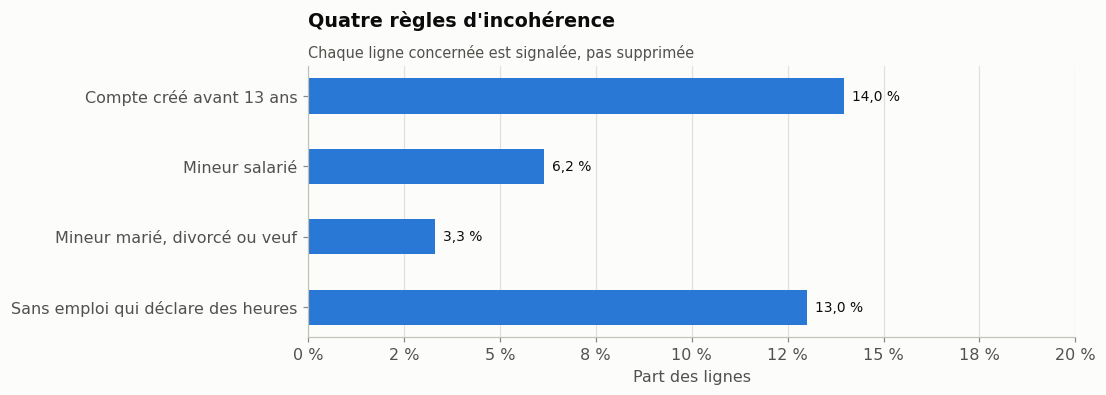

Lignes avec au moins une incohérence : 26,5 %
Part du stress expliquée par le temps passé : 70,7 % avec toutes les lignes, 71,4 % sans les lignes signalées


In [4]:
age_creation = df["age"] - (2025 - df["account_creation_year"])
drapeaux = pd.DataFrame({
    "flag_compte_avant_13_ans": age_creation < 13,
    "flag_mineur_salarie": (df["age"] < 18) & df["employment_status"].isin(["Full-time employed", "Part-time", "Freelancer"]),
    "flag_mineur_marie": (df["age"] < 18) & df["relationship_status"].isin(["Married", "Divorced", "Widowed"]),
    "flag_sans_emploi_avec_heures": df["employment_status"].isin(["Unemployed", "Retired"]) & (df["weekly_work_hours"] > 0),
})
REGLES = {"flag_compte_avant_13_ans": "Compte créé avant 13 ans",
          "flag_mineur_salarie": "Mineur salarié",
          "flag_mineur_marie": "Mineur marié, divorcé ou veuf",
          "flag_sans_emploi_avec_heures": "Sans emploi qui déclare des heures"}
parts_drapeaux = drapeaux.mean().mul(100).rename(REGLES)
signalees = drapeaux.any(axis=1)

propre = df[~signalees]
r2_propre = part_expliquee(propre, STRESS, propre[TEMPS] // 10)
r2_tout = part_expliquee(df, STRESS, df[TEMPS] // 10)

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(range(len(parts_drapeaux)), parts_drapeaux, height=0.5, color=BLEU)
for p, v in enumerate(parts_drapeaux):
    ax.text(v + 0.2, p, f"{fr(v)} %", va="center", fontsize=9, color=INK)
ax.set_yticks(range(len(parts_drapeaux)), parts_drapeaux.index)
ax.invert_yaxis()
ax.set_xlim(0, 20)
ax.xaxis.set_major_formatter(FORMAT_POURCENT)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Part des lignes")
titrer(ax, "Quatre règles d'incohérence", "Chaque ligne concernée est signalée, pas supprimée")
plt.show()

print(f"Lignes avec au moins une incohérence : {fr(signalees.mean() * 100, 1)} %")
print(f"Part du stress expliquée par le temps passé : {fr(r2_tout * 100, 1)} % avec toutes les lignes, "
      f"{fr(r2_propre * 100, 1)} % sans les lignes signalées")

**Ce que montrent les données**
- **27 %** des lignes ont au moins une incohérence : comptes créés avant 13 ans, mineurs salariés ou mariés, sans-emploi (chômeurs ou retraités) qui déclarent des heures de travail.
- Ces incohérences touchent l'emploi, la situation de couple, les heures de travail et l'année de création du compte. **Aucune de ces colonnes ne sert à la segmentation.**
- Sans les lignes signalées, le temps passé explique toujours **71 %** des écarts de stress : **les résultats ne dépendent pas de ces lignes.**

### 0.4 Variables inutiles

In [5]:
inutiles = pd.DataFrame({"constat": [
    f"une seule valeur : « {df['app_name'].iloc[0]} »",
    f"variation de {fr(df['daily_steps_count'].std() / df['daily_steps_count'].mean() * 100, 1)} % autour de la moyenne",
    f"égale aux minutes ÷ sessions (écart maximal : {fr((df[TEMPS] / df['sessions_per_day'] - df['average_session_length_minutes']).abs().max(), 2)} min)",
]}, index=["app_name", "daily_steps_count", "average_session_length_minutes"]).rename_axis("colonne")
display(inutiles)

,constat
colonne,
app_name,une seule valeur : « Instagram »
daily_steps_count,"variation de 1,1 % autour de la moyenne"
average_session_length_minutes,égale aux minutes ÷ sessions (écart maximal : ...


### 0.5 Quel fichier croire, et sur quels champs ?

Instagram nous a envoyé **deux versions presque identiques** de la réplique (« usage » et « users »). L'une a subi un nettoyage non documenté. La consigne nous demande de décider laquelle croire, champ par champ.

In [6]:
if CHEMIN_AUTRE.exists():
    autre = pd.read_csv(CHEMIN_AUTRE)
    differences = pd.Series({c: int((df[c].astype(str) != autre[c].astype(str)).sum()) for c in autre.columns})
    print(f"Mêmes utilisateurs dans le même ordre : {df['user_id'].equals(autre['user_id'])}")
    print(f"Colonnes identiques : {int((differences == 0).sum())} sur {len(differences)}")
    afficher(differences[differences > 0].rename("lignes différentes").to_frame().rename_axis("colonne"), 0)
    mineurs = df["age"] < 18
    afficher(pd.DataFrame({
        "fichier usage (analysé)": {
            "part déclarée salariée à temps plein (%)": (df.loc[mineurs, "employment_status"] == "Full-time employed").mean() * 100,
            "heures de travail par semaine (moyenne)": df.loc[mineurs, "weekly_work_hours"].mean()},
        "fichier users (autre version)": {
            "part déclarée salariée à temps plein (%)": (autre.loc[mineurs, "employment_status"] == "Full-time employed").mean() * 100,
            "heures de travail par semaine (moyenne)": autre.loc[mineurs, "weekly_work_hours"].mean()}}))
    COLONNES_UTILISEES = [STRESS, BONHEUR, TEMPS, "age", "sleep_hours_per_night", "daily_steps_count", "exercise_hours_per_week",
                          "sessions_per_day", "average_session_length_minutes", "likes_given_per_day", "comments_written_per_day",
                          "posts_created_per_week", "dms_sent_per_week", "privacy_setting_level", "country"]
    identiques = all(df[c].astype(str).equals(autre[c].astype(str)) for c in COLONNES_UTILISEES)
    print(f"Les colonnes utilisées dans l'analyse sont identiques dans les deux fichiers : {identiques}")
    del autre
else:
    print("Fichier instagram_users_lifestyleSafe.csv absent : la comparaison n'est pas recalculée.")

Mêmes utilisateurs dans le même ordre : True
Colonnes identiques : 52 sur 58


,lignes différentes
colonne,
employment_status,18 913
education_level,1 203
relationship_status,6 623
has_children,5 329
weekly_work_hours,18 912
account_creation_year,31 772


,fichier usage (analysé),fichier users (autre version)
part déclarée salariée à temps plein (%),"45,4","0,0"
heures de travail par semaine (moyenne),"40,0","0,0"


Les colonnes utilisées dans l'analyse sont identiques dans les deux fichiers : True


**Notre décision**
- Les deux fichiers ont les mêmes utilisateurs et **52 colonnes sur 58 identiques**. Dans le fichier `usage`, 45 % des 13–17 ans sont déclarés salariés à temps plein : le fichier `users` a corrigé cette incohérence.
- **Toutes les colonnes que nous utilisons** sont **identiques dans les deux fichiers** : nos résultats ne dépendent pas de ce choix. Nous travaillons sur le fichier `usage`.
- **Pour l'emploi et les heures de travail**, nous faisons confiance au fichier `users`. Nous n'utilisons pas ces colonnes.

### 0.6 Les variables construites
- **Six segments de temps passé** (S1 à S6), dont les seuils séparent les niveaux de stress et de bonheur : moins de 20 min, 20–88 min, 88–188 min, 188–240 min, 240–290 min, plus de 290 min.
- **Quatre groupes d'âge** (13–17, 18–34, 35–54, 55–65 ans) : les mineurs à part, pour des raisons légales.
- **Un indicateur « stress élevé »** (27 ou plus sur 40).

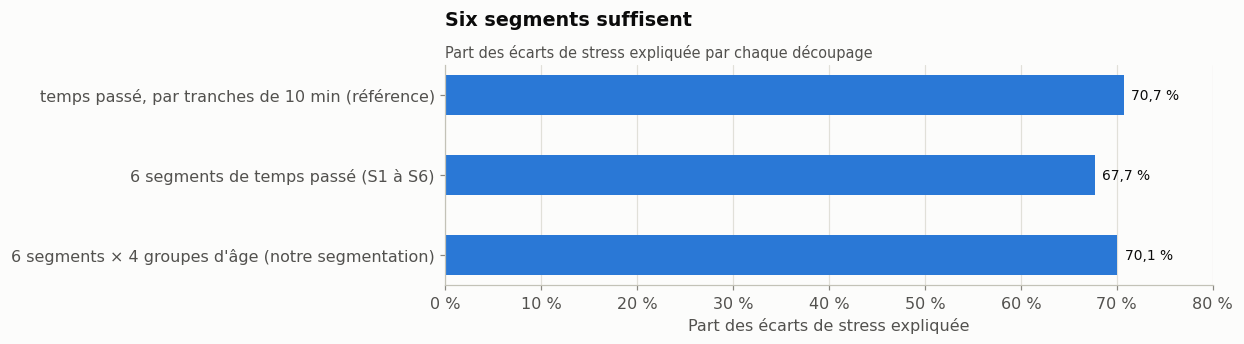

,part (%)
niveau de stress,
faible (0–13),"34,1"
modéré (14–26),"31,7"
élevé (27–40),"34,2"


In [7]:
df["heures"] = df[TEMPS] / 60
df["tranche_10min"] = (df[TEMPS] // 10).astype(int)
df["tranche_30min"] = ((df[TEMPS] // 30) * 30).astype(int)
df["segment"] = pd.cut(df[TEMPS], BORNES_SEGMENTS, right=False, labels=SEGMENTS)
df["tranche_age"] = pd.cut(df["age"], [13, 18, 25, 35, 45, 55, 66], right=False, labels=TRANCHES_AGE)
df["groupe_age"] = pd.cut(df["age"], BORNES_GROUPES_AGE, right=False, labels=GROUPES_AGE)
df["stress_eleve"] = df[STRESS] >= 27
df["tres_heureux"] = df[BONHEUR] >= 9
df["tres_malheureux"] = df[BONHEUR] <= 2
df["tranche_10min_age"] = df["tranche_10min"].astype(str) + "_" + df["age"].astype(str)
df["stress_temps_egal"] = a_temps_egal(df, STRESS)
df["bonheur_temps_egal"] = a_temps_egal(df, BONHEUR)

apport = pd.Series({
    "temps passé, par tranches de 10 min (référence)": part_expliquee(df, STRESS, ["tranche_10min"]) * 100,
    "6 segments de temps passé (S1 à S6)": part_expliquee(df, STRESS, ["segment"]) * 100,
    "6 segments × 4 groupes d'âge (notre segmentation)": part_expliquee(df, STRESS, ["segment", "groupe_age"]) * 100,
})
fig, ax = plt.subplots(figsize=(9, 2.6))
ax.barh(range(len(apport)), apport, height=0.5, color=BLEU)
for p, v in enumerate(apport):
    ax.text(v + 0.8, p, f"{fr(v)} %", va="center", fontsize=9, color=INK)
ax.set_yticks(range(len(apport)), apport.index)
ax.invert_yaxis()
ax.set_xlim(0, 80)
ax.xaxis.set_major_formatter(FORMAT_POURCENT)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Part des écarts de stress expliquée")
titrer(ax, "Six segments suffisent", "Part des écarts de stress expliquée par chaque découpage")
plt.show()

niveaux = pd.cut(df[STRESS], [-1, 13, 26, 40], labels=["faible (0–13)", "modéré (14–26)", "élevé (27–40)"])
afficher(niveaux.value_counts(normalize=True).mul(100).sort_index().to_frame("part (%)").rename_axis("niveau de stress"))

> **Ce qu'on retient :** le fichier est complet et sans doublon ; les incohérences sont signalées sans changer les résultats ; les six segments de temps conservent presque toute l'information du temps passé (68 % des écarts de stress expliqués, contre 71 % avec le temps à 10 minutes près).

---
## 1. Les hypothèses non concluantes

Plusieurs pistes, appuyées par des sources de santé publique, **ne se vérifient pas dans notre panel** : le sommeil, l'activité physique (pas et sport) et le pays. Un indicateur sans lien avec l'usage est aussi un résultat. La durée des sessions est traitée avec la fréquence de connexion (partie 4.4).

### 1.1 Le sommeil
**Questions :** Instagram fait-il baisser le nombre d'heures de sommeil ? Le manque de sommeil joue-t-il un rôle dans le bien-être ?

**Source :** [info.gouv.fr, « Santé mentale : pourquoi le sommeil joue un rôle clé », 2025](https://www.info.gouv.fr/actualite/sante-mentale-pourquoi-le-sommeil-joue-un-role-cle) — « Avoir une bonne santé du sommeil contribue à avoir une bonne santé mentale. »

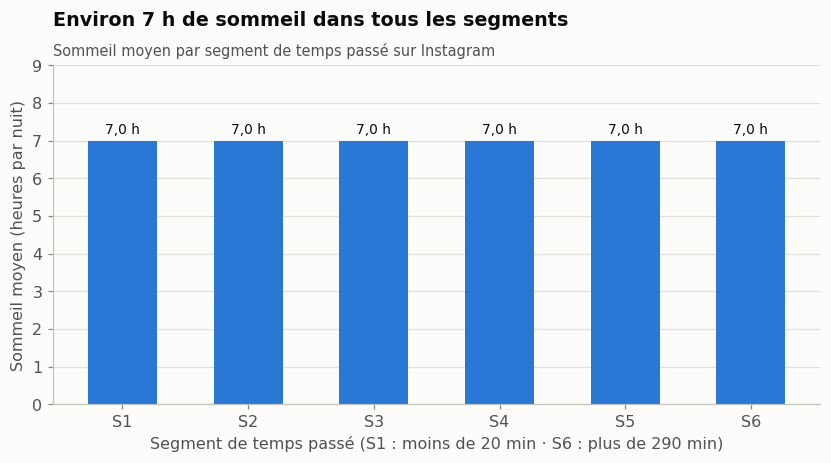

,n,sommeil_moyen,part_moins_de_6h
segment,,,
S1 Très occasionnel,14 512,"7,00","17,12"
S2 Occasionnel,27 884,"7,00","17,43"
S3 Modéré,57 823,"7,00","17,16"
S4 Soutenu,31 384,"7,00","16,83"
S5 Intensif,27 617,"6,99","17,42"
S6 Très intensif,40 780,"7,00","17,09"


In [8]:
sommeil = agreger(df, "segment", sommeil_moyen=("sleep_hours_per_night", "mean"),
                  part_moins_de_6h=("sleep_hours_per_night", lambda s: (s < 6).mean() * 100))
fig, ax = plt.subplots(figsize=(9, 4))
barres(ax, sommeil["sommeil_moyen"], COURTS, suffixe=" h")
ax.set_ylim(0, 9)
ax.set_xlabel("Segment de temps passé (S1 : moins de 20 min · S6 : plus de 290 min)")
ax.set_ylabel("Sommeil moyen (heures par nuit)")
titrer(ax, "Environ 7 h de sommeil dans tous les segments", "Sommeil moyen par segment de temps passé sur Instagram")
plt.show()
afficher(sommeil.rename_axis("segment"), 2)

Le sommeil moyen est d'environ **7 h** et la part de petits dormeurs (moins de 6 h) d'environ **17 %**, dans tous les segments.

### 1.2 L'activité physique : pas et sport
**Questions :** le temps passé sur Instagram fait-il baisser l'activité physique ? L'activité physique joue-t-elle un rôle sur le bien-être ?

**Source :** [Ameli, « Sport et activité physique : un atout pour le bien-être »](https://www.ameli.fr/assure/sante/themes/activite-physique-sante/sport-et-activite-physique-un-atout-pour-le-bien-etre) — l'activité physique réduit le stress et l'anxiété, régule l'humeur et améliore le sommeil.

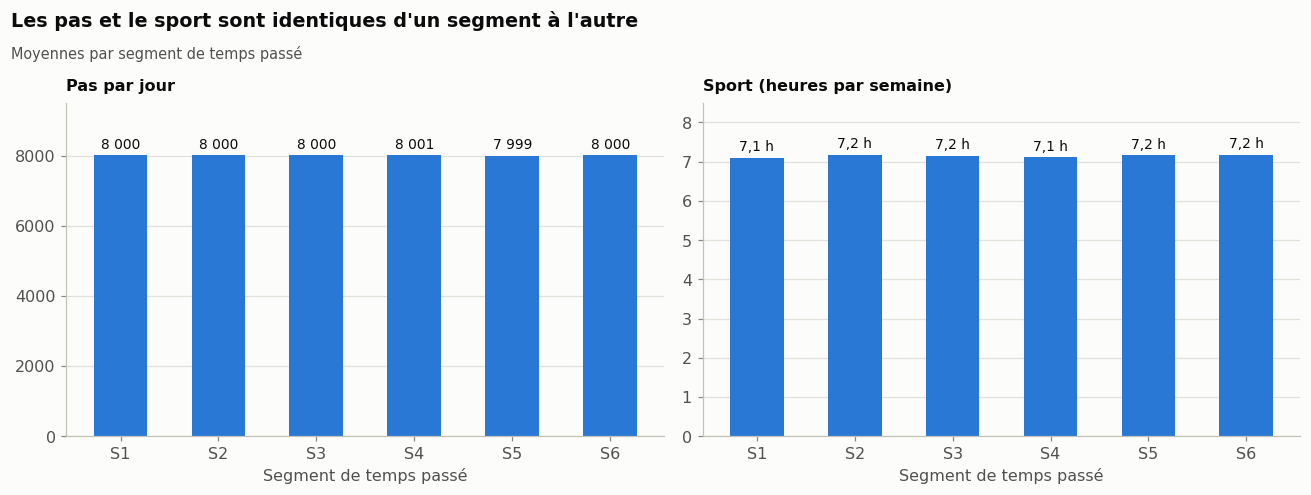

,lien avec le temps passé,lien avec le stress,lien avec le bonheur
Sommeil,"-0,001","0,000","0,003"
Pas par jour,"-0,002","-0,002","-0,005"
Sport,"0,001","-0,002","-0,007"


Pas par jour : 98 % des utilisateurs entre 7 794 et 8 208


In [9]:
activite = agreger(df, "segment", pas_par_jour=("daily_steps_count", "mean"), sport_heures_semaine=("exercise_hours_per_week", "mean"))
fig, (ax_g, ax_d) = plt.subplots(1, 2, figsize=(12, 4))
barres(ax_g, activite["pas_par_jour"], COURTS, decimales=0)
ax_g.set_ylim(0, 9500)
panneau(ax_g, "Pas par jour")
barres(ax_d, activite["sport_heures_semaine"], COURTS, suffixe=" h")
ax_d.set_ylim(0, 8.5)
panneau(ax_d, "Sport (heures par semaine)")
for ax in (ax_g, ax_d):
    ax.set_xlabel("Segment de temps passé")
fig.tight_layout()
titrer_figure(fig, "Les pas et le sport sont identiques d'un segment à l'autre", "Moyennes par segment de temps passé")
plt.show()

NOMS_VIE = (("sleep_hours_per_night", "Sommeil"), ("daily_steps_count", "Pas par jour"), ("exercise_hours_per_week", "Sport"))
afficher(pd.DataFrame({
    "lien avec le temps passé": {n: df[c].corr(df[TEMPS], method="spearman") for c, n in NOMS_VIE},
    "lien avec le stress": {n: df[c].corr(df[STRESS], method="spearman") for c, n in NOMS_VIE},
    "lien avec le bonheur": {n: df[c].corr(df[BONHEUR], method="spearman") for c, n in NOMS_VIE},
}), 3)
print(f"Pas par jour : 98 % des utilisateurs entre {fr(df['daily_steps_count'].quantile(0.01), 0)} et {fr(df['daily_steps_count'].quantile(0.99), 0)}")

Environ **8 000 pas par jour** et **7,2 h de sport par semaine** dans tous les segments. Le nombre de pas varie à peine : cette variable ne permet pas de distinguer des profils. Ni le sommeil, ni les pas, ni le sport ne sont liés au temps passé, au stress ou au bonheur (corrélations proches de 0).

### 1.3 Le pays

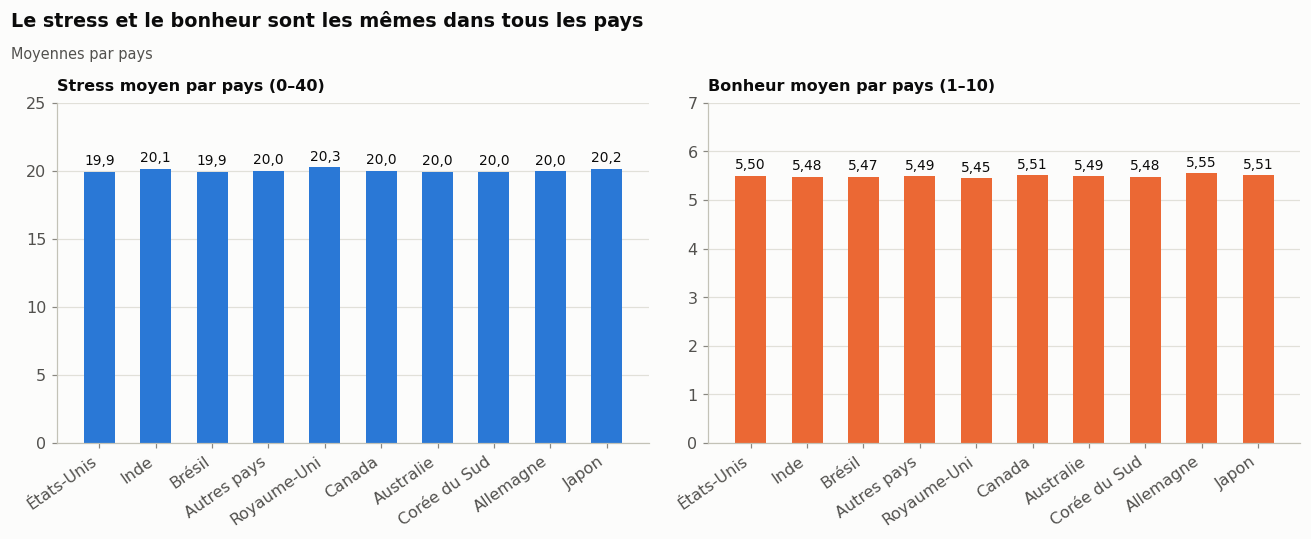

,n,minutes,stress,bonheur,stress_temps_egal,bonheur_temps_egal
pays,,,,,,
États-Unis,49 964,"187,67","19,94","5,50","20,04","5,49"
Inde,36 094,"189,95","20,14","5,48","20,02","5,48"
Brésil,23 865,"188,19","19,91","5,47","19,96","5,47"
Autres pays,20 157,"188,33","20,03","5,49","20,07","5,49"
Royaume-Uni,15 828,"191,36","20,26","5,45","20,02","5,47"
Canada,13 954,"188,36","20,00","5,51","20,04","5,51"
Australie,12 065,"188,67","19,95","5,49","19,95","5,49"
Corée du Sud,10 048,"188,74","19,95","5,48","19,93","5,47"
Allemagne,9 994,"187,19","19,96","5,55","20,09","5,53"


In [10]:
PAYS = {"United States": "États-Unis", "India": "Inde", "Brazil": "Brésil", "Other": "Autres pays",
        "United Kingdom": "Royaume-Uni", "Canada": "Canada", "Australia": "Australie",
        "South Korea": "Corée du Sud", "Germany": "Allemagne", "Japan": "Japon"}
pays = agreger(df, "country", minutes=(TEMPS, "mean"), stress=(STRESS, "mean"), bonheur=(BONHEUR, "mean"),
               stress_temps_egal=("stress_temps_egal", "mean"), bonheur_temps_egal=("bonheur_temps_egal", "mean"))
pays.index = [PAYS[p] for p in pays.index]
pays = pays.sort_values("n", ascending=False)

fig, (ax_g, ax_d) = plt.subplots(1, 2, figsize=(12, 4.4))
barres(ax_g, pays["stress"], pays.index, rotation=35)
ax_g.set_ylim(0, 25)
panneau(ax_g, "Stress moyen par pays (0–40)")
barres(ax_d, pays["bonheur"], pays.index, couleur=ORANGE, decimales=2, rotation=35)
ax_d.set_ylim(0, 7)
panneau(ax_d, "Bonheur moyen par pays (1–10)")
fig.tight_layout()
titrer_figure(fig, "Le stress et le bonheur sont les mêmes dans tous les pays", "Moyennes par pays")
plt.show()
afficher(pays.rename_axis("pays"), 2)

Dans les 10 pays, le stress moyen reste entre **19,9 et 20,3** et le bonheur entre **5,45 et 5,55**, avec le même temps passé (environ 3 h 10 par jour). À temps égal, les écarts sont inférieurs à 0,1 point.

> **Ce qu'on retient :** le sommeil, l'activité physique et le pays **ne sont pas liés** à l'usage d'Instagram ni au bien-être dans notre panel. Nos sources laissaient attendre un effet du sommeil et du sport : c'est une limite de la réplique synthétique (partie 8).

---
## 2. Le temps passé sur Instagram : le cœur du lien

### 2.1 Le temps passé est-il le facteur le plus lié au stress ?

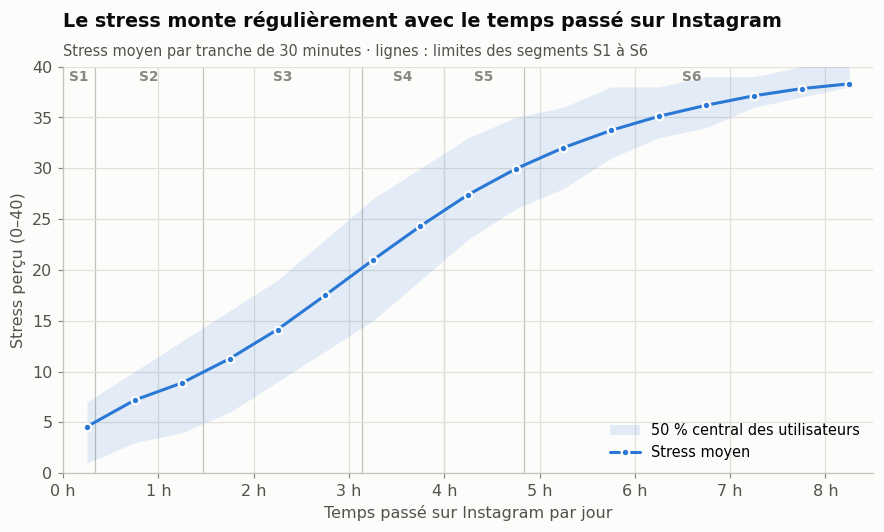

Stress en plus par heure : +5,4 points · part du stress expliquée par le temps passé : 71 %


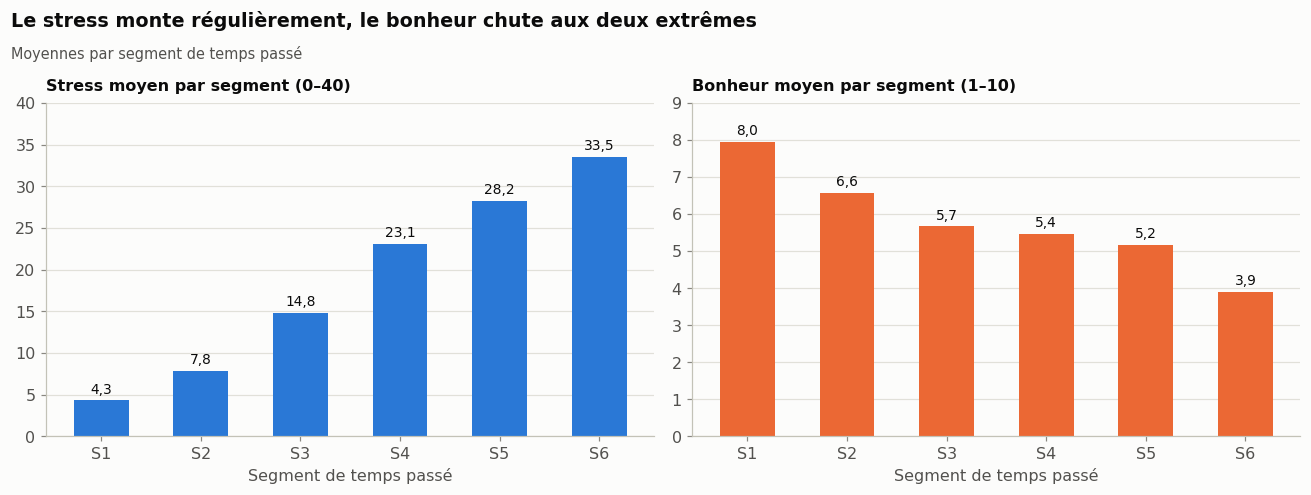

,temps par jour,utilisateurs,temps moyen (min),stress (0–40),bonheur (1–10),stress élevé (%)
segment,,,,,,
S1 Très occasionnel,< 20 min,14 512,"7,0","4,3","8,0","0,0"
S2 Occasionnel,20–88 min,27 884,"56,4","7,8","6,6","0,2"
S3 Modéré,88–188 min,57 823,"138,8","14,8","5,7","7,8"
S4 Soutenu,188–240 min,31 384,"213,2","23,1","5,4","34,5"
S5 Intensif,240–290 min,27 617,"263,7","28,2","5,2","61,2"
S6 Très intensif,> 290 min,40 780,"345,1","33,5","3,9","88,7"


In [11]:
t30 = agreger(df, "tranche_30min", stress=(STRESS, "mean"), bonheur=(BONHEUR, "mean"),
              q1=(STRESS, lambda s: s.quantile(0.25)), q3=(STRESS, lambda s: s.quantile(0.75)))
x30 = (t30.index + 15) / 60
pente = np.polyfit(df["heures"], df[STRESS], 1)[0]
r2_stress = part_expliquee(df, STRESS, ["tranche_10min"])
r2_bonheur = part_expliquee(df, BONHEUR, ["tranche_10min"])

fig, ax = plt.subplots(figsize=(9.5, 4.8))
ax.fill_between(x30, t30["q1"], t30["q3"], color=to_rgba(BLEU, 0.12), linewidth=0, label="50 % central des utilisateurs")
ax.plot(x30, t30["stress"], color=BLEU, marker="o", markersize=5, markeredgecolor=SURFACE, markeredgewidth=1.5, label="Stress moyen")
for borne in BORNES_SEGMENTS[1:-1]:
    ax.axvline(borne / 60, color=AXIS, linewidth=0.8, zorder=0)
for x, nom in zip([10 / 60, 54 / 60, 138 / 60, 214 / 60, 265 / 60, 6.6], COURTS):
    ax.text(x, 38.6, nom, ha="center", fontsize=9, color=MUTED, fontweight="semibold")
ax.set_xlim(0, 8.5)
ax.set_ylim(0, 40)
ax.xaxis.set_major_formatter(FORMAT_HEURES)
ax.set_xlabel("Temps passé sur Instagram par jour")
ax.set_ylabel("Stress perçu (0–40)")
ax.legend(loc="lower right")
titrer(ax, "Le stress monte régulièrement avec le temps passé sur Instagram",
       "Stress moyen par tranche de 30 minutes · lignes : limites des segments S1 à S6")
plt.show()
print(f"Stress en plus par heure : +{fr(pente)} points · part du stress expliquée par le temps passé : {fr(r2_stress * 100, 0)} %")

segments_temps = agreger(df, "segment", minutes=(TEMPS, "mean"), stress=(STRESS, "mean"), bonheur=(BONHEUR, "mean"),
                         part_stress_eleve=("stress_eleve", lambda s: s.mean() * 100))
fig, (ax_g, ax_d) = plt.subplots(1, 2, figsize=(12, 4))
barres(ax_g, segments_temps["stress"], COURTS)
ax_g.set_ylim(0, 40)
panneau(ax_g, "Stress moyen par segment (0–40)")
barres(ax_d, segments_temps["bonheur"], COURTS, couleur=ORANGE)
ax_d.set_ylim(0, 9)
panneau(ax_d, "Bonheur moyen par segment (1–10)")
for ax in (ax_g, ax_d):
    ax.set_xlabel("Segment de temps passé")
fig.tight_layout()
titrer_figure(fig, "Le stress monte régulièrement, le bonheur chute aux deux extrêmes", "Moyennes par segment de temps passé")
plt.show()

tableau_segments = segments_temps.copy()
tableau_segments.insert(0, "temps par jour", DUREES_SEGMENTS)
afficher(tableau_segments.rename(columns={"n": "utilisateurs", "minutes": "temps moyen (min)", "stress": "stress (0–40)",
                                          "bonheur": "bonheur (1–10)", "part_stress_eleve": "stress élevé (%)"}).rename_axis("segment"))

**Ce que montrent les données**
- Le stress **monte régulièrement** : environ **+5,4 points par heure**, de 4,3 en S1 à 33,5 en S6. Le temps passé explique à lui seul **71 %** des écarts de stress.
- Le bonheur, lui, **chute surtout aux deux extrêmes** : de 8,0 en S1 à 6,6 en S2, puis il reste entre 5,7 et 5,2 de S3 à S5, avant de tomber à 3,9 en S6.
- Les **seuils de 20 min et d'environ 4 h 50** (290 min) marquent ces deux chutes : c'est ce que la segmentation apporte de plus qu'un simple classement par temps passé.

**Conclusion pour les équipes produit :** le temps quotidien passé sur l'application est **l'indicateur numéro un** à suivre pour repérer les groupes d'utilisateurs les plus stressés. Instagram le mesure déjà pour tous ses utilisateurs, sans rien leur demander.

**Sources :** [Riehm et al., 2019 (Johns Hopkins)](https://hub.jhu.edu/2019/09/11/social-media-teen-mental-health/) — au-delà de 3 h par jour, le risque d'anxiété et de dépression des adolescents augmente · [Liu et al., 2022, méta-analyse](https://pmc.ncbi.nlm.nih.gov/articles/PMC9103874/) — chaque heure de plus par jour va avec environ 13 % de risque de dépression en plus.

> **Ce qu'on retient :** oui, **le temps passé est le facteur d'usage le plus lié au stress**, de façon régulière, et il est aussi lié au bonheur, surtout aux deux extrêmes.

### 2.2 Le temps passé chaque jour est-il aussi lié au bonheur ?

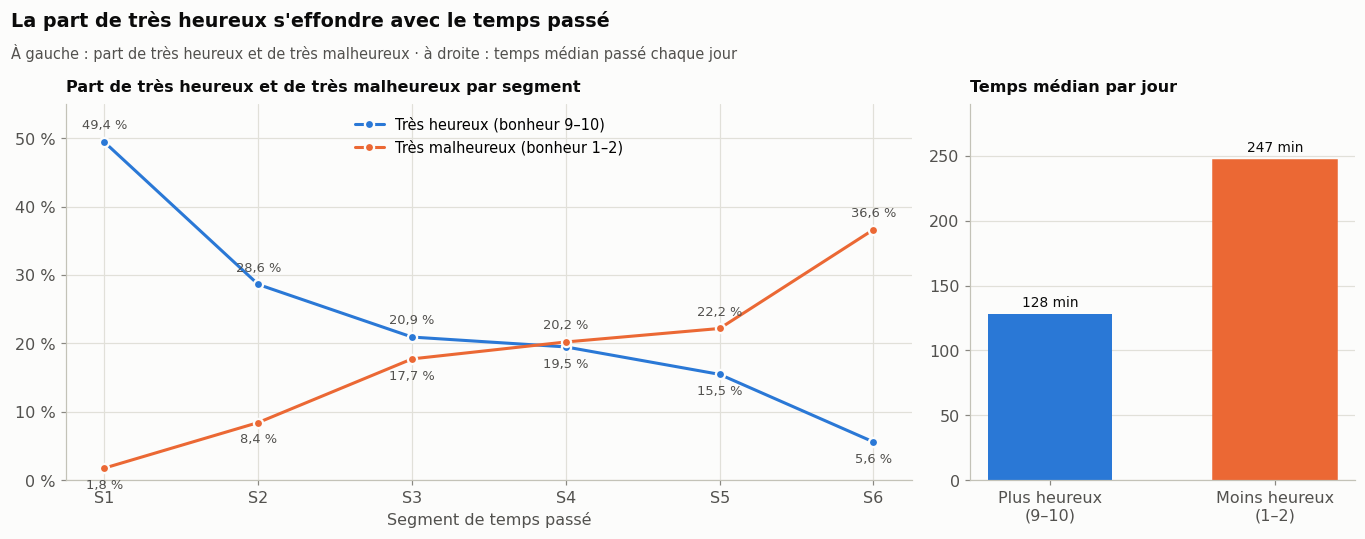

,n,part_tres_heureux,part_tres_malheureux
segment,,,
S1 Très occasionnel,14 512,"49,4","1,8"
S2 Occasionnel,27 884,"28,6","8,4"
S3 Modéré,57 823,"20,9","17,7"
S4 Soutenu,31 384,"19,5","20,2"
S5 Intensif,27 617,"15,5","22,2"
S6 Très intensif,40 780,"5,6","36,6"


,Plus heureux (9–10),Autres,Moins heureux (1–2)
temps médian par jour (min),"128,0","202,0","247,0"
le quart qui y passe le moins : moins de (min),"44,0","118,0","164,0"
sessions par jour,"7,3","11,1","13,6"


In [12]:
bonheur_segments = agreger(df, "segment", part_tres_heureux=("tres_heureux", lambda s: s.mean() * 100),
                           part_tres_malheureux=("tres_malheureux", lambda s: s.mean() * 100))
profils_temps = pd.DataFrame({
    groupe: {"temps médian par jour (min)": df.loc[masque, TEMPS].median(),
             "le quart qui y passe le moins : moins de (min)": df.loc[masque, TEMPS].quantile(0.25),
             "sessions par jour": df.loc[masque, "sessions_per_day"].mean()}
    for groupe, masque in (("Plus heureux (9–10)", df["tres_heureux"]), ("Autres", ~df["tres_heureux"]),
                           ("Moins heureux (1–2)", df["tres_malheureux"]))})

fig, (ax_g, ax_d) = plt.subplots(1, 2, figsize=(12.5, 4.4), gridspec_kw={"width_ratios": [2.2, 1]})
positions = np.arange(len(bonheur_segments))
heureux, malheureux = bonheur_segments["part_tres_heureux"].to_numpy(), bonheur_segments["part_tres_malheureux"].to_numpy()
for valeurs, autres, couleur, nom in ((heureux, malheureux, BLEU, "Très heureux (bonheur 9–10)"),
                                      (malheureux, heureux, ORANGE, "Très malheureux (bonheur 1–2)")):
    ax_g.plot(positions, valeurs, color=couleur, marker="o", markersize=6, markeredgecolor=SURFACE, markeredgewidth=1.5, label=nom)
    for p, v, w in zip(positions, valeurs, autres):
        dessus = v >= w
        ax_g.text(p, v + (1.5 if dessus else -1.5), f"{fr(v)} %", ha="center", va="bottom" if dessus else "top", fontsize=8.5, color=INK2)
ax_g.set_xticks(positions, COURTS)
ax_g.set_ylim(0, 55)
ax_g.yaxis.set_major_formatter(FORMAT_POURCENT)
ax_g.set_xlabel("Segment de temps passé")
ax_g.legend(loc="upper center")
panneau(ax_g, "Part de très heureux et de très malheureux par segment")
medianes = profils_temps.loc["temps médian par jour (min)", ["Plus heureux (9–10)", "Moins heureux (1–2)"]]
barres(ax_d, medianes, ["Plus heureux\n(9–10)", "Moins heureux\n(1–2)"], decimales=0, suffixe=" min")
ax_d.patches[1].set_color(ORANGE)
ax_d.set_ylim(0, 290)
panneau(ax_d, "Temps médian par jour")
fig.tight_layout()
titrer_figure(fig, "La part de très heureux s'effondre avec le temps passé",
              "À gauche : part de très heureux et de très malheureux · à droite : temps médian passé chaque jour")
plt.show()
afficher(bonheur_segments.rename_axis("segment"))
afficher(profils_temps)

- En S1 (moins de 20 min par jour), près de **la moitié** des utilisateurs sont très heureux ; en S6 (plus de 290 min), ils ne sont plus que **6 %**, et plus d'un tiers sont très malheureux.
- Les plus heureux passent **deux fois moins de temps** sur l'application que les moins heureux, et ouvrent l'application moins souvent.

**Note : le temps passé et l'activité disent la même chose.** Les compteurs d'activité (likes, stories, commentaires, messages, publicités, sessions) sont presque des copies du temps passé : plus on reste, plus on agit. Ils n'apportent donc pas d'information en plus (partie 4).

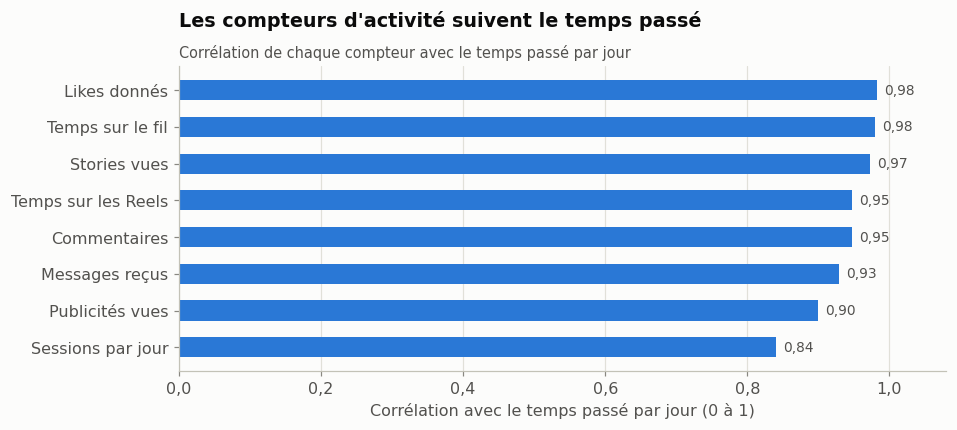

In [13]:
ACTIVITE = {"likes_given_per_day": "Likes donnés", "stories_viewed_per_day": "Stories vues",
            "time_on_feed_per_day": "Temps sur le fil", "time_on_reels_per_day": "Temps sur les Reels",
            "comments_written_per_day": "Commentaires", "dms_received_per_week": "Messages reçus",
            "ads_viewed_per_day": "Publicités vues", "sessions_per_day": "Sessions par jour"}
copies = pd.Series({nom: df[c].corr(df[TEMPS], method="spearman") for c, nom in ACTIVITE.items()}).sort_values()
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(range(len(copies)), copies, height=0.55, color=BLEU)
for p, v in enumerate(copies):
    ax.text(v + 0.01, p, fr(v, 2), va="center", fontsize=9, color=INK2)
ax.set_yticks(range(len(copies)), copies.index)
ax.set_xlim(0, 1.08)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: fr(v, 1)))
ax.grid(axis="y", visible=False)
ax.set_xlabel("Corrélation avec le temps passé par jour (0 à 1)")
titrer(ax, "Les compteurs d'activité suivent le temps passé", "Corrélation de chaque compteur avec le temps passé par jour")
plt.show()

> **Ce qu'on retient :** le temps passé est aussi lié au bonheur : **les plus heureux sont ceux qui utilisent le moins Instagram**, en temps comme en nombre de sessions.

---
## 3. Le rôle de l'âge

### 3.1 D'après l'âge, à usage égal, qui est le plus stressé ?
Pour comparer des utilisateurs à **usage égal**, on regarde le segment **S4 Soutenu** (188 à 240 min par jour, environ 3 h 30 en moyenne dans chaque tranche d'âge).

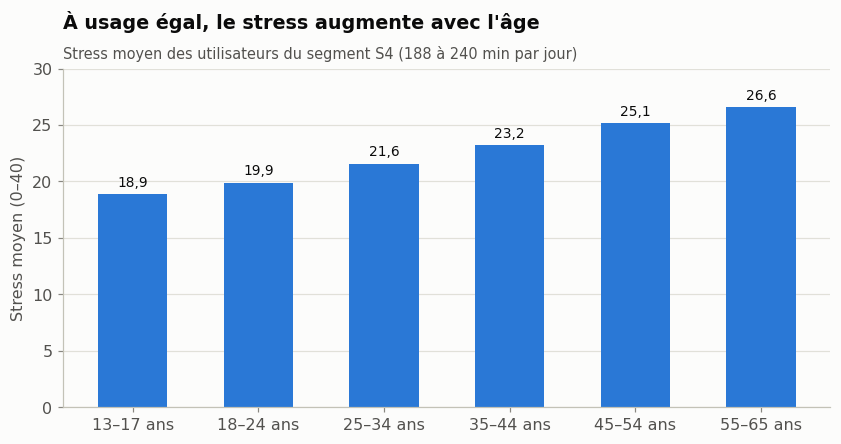

,n,minutes,stress
âge,,,
13–17 ans,2 946,"213,6","18,9"
18–24 ans,4 264,"213,0","19,9"
25–34 ans,6 017,"213,3","21,6"
35–44 ans,5 950,"213,3","23,2"
45–54 ans,5 835,"213,3","25,1"
55–65 ans,6 372,"212,8","26,6"


À temps égal, chaque tranche de 10 ans d'âge en plus va avec +1,2 point de stress.


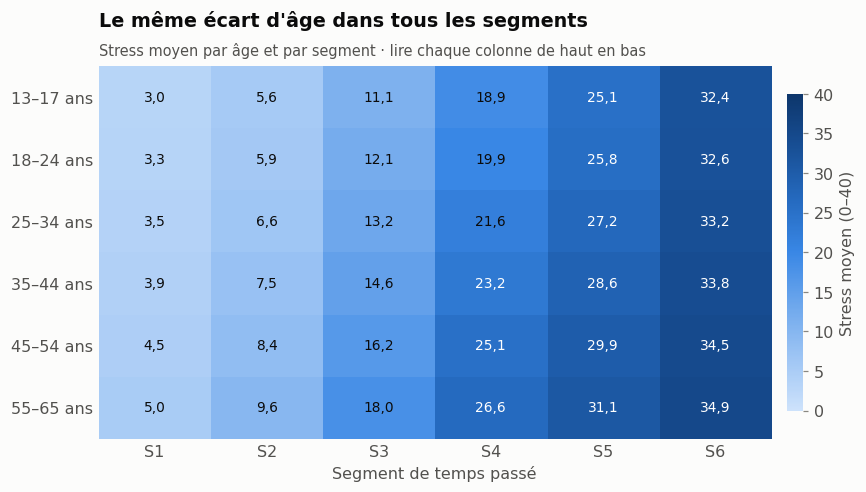

In [14]:
age_s4 = agreger(df[df["segment"] == "S4 Soutenu"], "tranche_age", minutes=(TEMPS, "mean"), stress=(STRESS, "mean"))
ecart = df[STRESS] - df.groupby("tranche_10min")[STRESS].transform("mean")
pente_age = np.polyfit(df["age"], ecart, 1)[0] * 10

fig, ax = plt.subplots(figsize=(9, 4))
barres(ax, age_s4["stress"], age_s4.index)
ax.set_ylim(0, 30)
ax.set_ylabel("Stress moyen (0–40)")
titrer(ax, "À usage égal, le stress augmente avec l'âge", "Stress moyen des utilisateurs du segment S4 (188 à 240 min par jour)")
plt.show()
afficher(age_s4.rename_axis("âge"))
print(f"À temps égal, chaque tranche de 10 ans d'âge en plus va avec +{fr(pente_age, 1)} point de stress.")

grille_age = agreger(df, ["tranche_age", "segment"], stress=(STRESS, "mean"))["stress"].unstack("segment")
grille_age.columns = COURTS
fig, ax = plt.subplots(figsize=(9.5, 4.4))
carte_chaleur(ax, grille_age, 0, 40, "Stress moyen (0–40)", decimales=1)
ax.set_xlabel("Segment de temps passé")
titrer(ax, "Le même écart d'âge dans tous les segments", "Stress moyen par âge et par segment · lire chaque colonne de haut en bas")
plt.show()

- En S4, le stress passe de **18,9** chez les 13–17 ans à **26,6** chez les 55–65 ans.
- À temps égal, le stress augmente de **+1,2 point par tranche de 10 ans**, et le même écart se retrouve dans tous les segments.

> **Ce qu'on retient :** **à usage égal, ce sont les plus âgés qui sont les plus stressés.** L'âge apporte une information en plus du temps passé.

### 3.2 Les plus jeunes passent-ils plus de temps sur Instagram ?

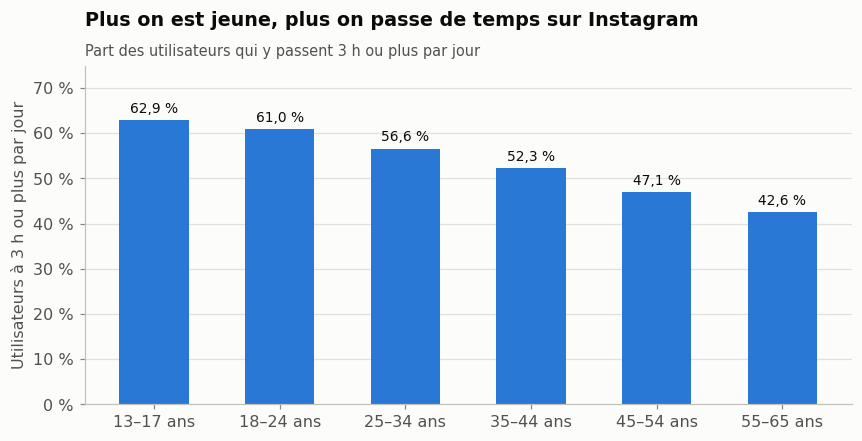

,n,minutes,part_3h_ou_plus
âge,,,
13–17 ans,18 913,"222,7","62,9"
18–24 ans,26 169,"215,1","61,0"
25–34 ans,38 097,"202,4","56,6"
35–44 ans,37 914,"188,1","52,3"
45–54 ans,37 652,"172,9","47,1"
55–65 ans,41 255,"158,8","42,6"


In [15]:
exposition = agreger(df, "tranche_age", minutes=(TEMPS, "mean"), part_3h_ou_plus=(TEMPS, lambda s: (s >= 180).mean() * 100))
fig, ax = plt.subplots(figsize=(9, 4))
barres(ax, exposition["part_3h_ou_plus"], exposition.index, suffixe=" %")
ax.set_ylim(0, 75)
ax.yaxis.set_major_formatter(FORMAT_POURCENT)
ax.set_ylabel("Utilisateurs à 3 h ou plus par jour")
titrer(ax, "Plus on est jeune, plus on passe de temps sur Instagram", "Part des utilisateurs qui y passent 3 h ou plus par jour")
plt.show()
afficher(exposition.rename_axis("âge"))

**63 %** des 13–17 ans passent 3 h ou plus par jour sur Instagram, contre **43 %** des 55–65 ans. Le temps moyen baisse de 223 à 159 minutes par jour.

**Conclusion pour les équipes produit :** les plus jeunes sont **les plus exposés** en temps passé. Ce sont eux que les outils de limitation de temps touchent le plus souvent, et ils incluent des **mineurs**, qui demandent des précautions particulières.

**Source :** [question écrite à l'Assemblée nationale citant le rapport « Enfants et écrans » (2024)](https://www.assemblee-nationale.fr/dyn/16/questions/QANR5L16QE18298.pdf) — chez les 16–19 ans, le temps d'écran dépasse les cinq heures ; les experts évoquent la nocivité des réseaux sociaux, « facteur de risque » de dépression ou d'anxiété en cas de « vulnérabilité préexistante ».

> **Ce qu'on retient :** deux effets opposés : les jeunes sont **plus exposés en temps**, les plus âgés sont **plus stressés à temps égal**.

---
## 4. Les habitudes d'utilisation

Ces parties comparent des **façons d'utiliser Instagram**. Chaque fois, on vérifie si l'écart tient encore **à temps passé égal**.

### 4.1 Les moins heureux ont un usage plus intensif
Comparaison des **moins heureux** (bonheur de 1 ou 2) et des **plus heureux** (bonheur de 9 ou 10).

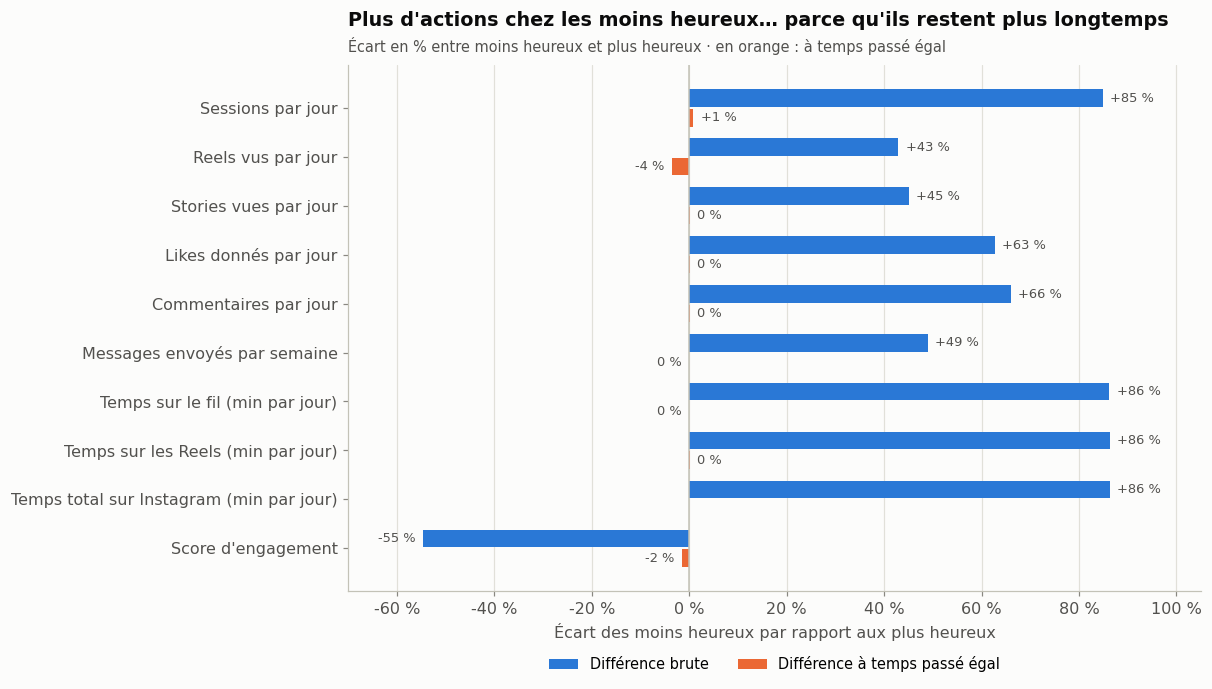

,moins heureux (1–2),plus heureux (9–10),différence (%),différence à temps égal (%)
comportement,,,,
Sessions par jour,"13,6","7,3","84,8","0,9"
Reels vus par jour,"206,9","144,8","42,9","-3,6"
Stories vues par jour,"119,4","82,3","45,1","0,0"
Likes donnés par jour,"148,4","91,2","62,7","0,1"
Commentaires par jour,"43,0","25,9","66,0","0,0"
Messages envoyés par semaine,"34,6","23,3","49,0","-0,1"
Temps sur le fil (min par jour),"123,3","66,2","86,2","0,0"
Temps sur les Reels (min par jour),"74,1","39,8","86,4","0,1"
Temps total sur Instagram (min par jour),"246,8","132,4","86,3",—


Score d'engagement : corrélé à -0,80 avec le temps passé et à 0,94 avec les likes et commentaires par minute.


In [16]:
COMPORTEMENTS = {"sessions_per_day": "Sessions par jour", "reels_watched_per_day": "Reels vus par jour",
                 "stories_viewed_per_day": "Stories vues par jour", "likes_given_per_day": "Likes donnés par jour",
                 "comments_written_per_day": "Commentaires par jour", "dms_sent_per_week": "Messages envoyés par semaine",
                 "time_on_feed_per_day": "Temps sur le fil (min par jour)", "time_on_reels_per_day": "Temps sur les Reels (min par jour)",
                 TEMPS: "Temps total sur Instagram (min par jour)", "user_engagement_score": "Score d'engagement"}
lignes = []
for colonne, nom in COMPORTEMENTS.items():
    moins, plus = df.loc[df["tres_malheureux"], colonne].mean(), df.loc[df["tres_heureux"], colonne].mean()
    if colonne == TEMPS:
        ecart_egal = np.nan
    else:
        egale = a_temps_egal(df, colonne)
        ecart_egal = (egale[df["tres_malheureux"]].mean() / egale[df["tres_heureux"]].mean() - 1) * 100
    lignes.append((nom, moins, plus, (moins / plus - 1) * 100, ecart_egal))
usage = pd.DataFrame(lignes, columns=["comportement", "moins heureux (1–2)", "plus heureux (9–10)",
                                      "différence (%)", "différence à temps égal (%)"]).set_index("comportement")

fig, ax = plt.subplots(figsize=(10, 6.2))
y = np.arange(len(usage))
for k, (colonne, couleur, nom) in enumerate((("différence (%)", BLEU, "Différence brute"),
                                             ("différence à temps égal (%)", ORANGE, "Différence à temps passé égal"))):
    positions = y - 0.2 + 0.4 * k
    valeurs = usage[colonne].fillna(0)
    ax.barh(positions, valeurs, height=0.36, color=couleur, label=nom)
    for p, v, brut in zip(positions, valeurs, usage[colonne]):
        if not pd.isna(brut):
            ax.text(v + (1.5 if v >= 0 else -1.5), p, f"{'+' if v > 0.5 else ''}{fr(v, 0)} %", va="center",
                    ha="left" if v >= 0 else "right", fontsize=8.5, color=INK2)
ax.axvline(0, color=AXIS, linewidth=1)
ax.set_yticks(y, usage.index)
ax.invert_yaxis()
ax.set_xlim(-70, 105)
ax.xaxis.set_major_formatter(FORMAT_POURCENT)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Écart des moins heureux par rapport aux plus heureux")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
titrer(ax, "Plus d'actions chez les moins heureux… parce qu'ils restent plus longtemps",
       "Écart en % entre moins heureux et plus heureux · en orange : à temps passé égal")
plt.show()
afficher(usage)
df["interactions_par_minute"] = (df["likes_given_per_day"] + df["comments_written_per_day"]) / df[TEMPS]
print(f"Score d'engagement : corrélé à {fr(df['user_engagement_score'].corr(df[TEMPS], method='spearman'), 2)} avec le temps passé "
      f"et à {fr(df['user_engagement_score'].corr(df['interactions_par_minute'], method='spearman'), 2)} avec les likes et commentaires par minute.")

- Les moins heureux **utilisent davantage toutes les fonctionnalités** : sessions, Reels, stories, likes, commentaires, messages. Le vrai constat est un **usage beaucoup plus intensif**, d'abord en temps (+86 %).
- Les plus heureux font moins d'actions mais ont un **score d'engagement deux fois plus élevé**. Ce score mesure surtout les interactions **par minute**, élevées chez ceux qui restent peu de temps.
- **À temps passé égal, les écarts deviennent presque nuls** (moins de 5 %), y compris celui du score d'engagement (barres orange).

> **Ce qu'on retient :** les moins heureux ont un usage **plus intensif**, mais à temps égal ils agissent exactement comme les plus heureux. Ce n'est pas la qualité des interactions qui les distingue, c'est **le temps passé**.

### 4.2 Consommateurs ou créateurs de contenu ?

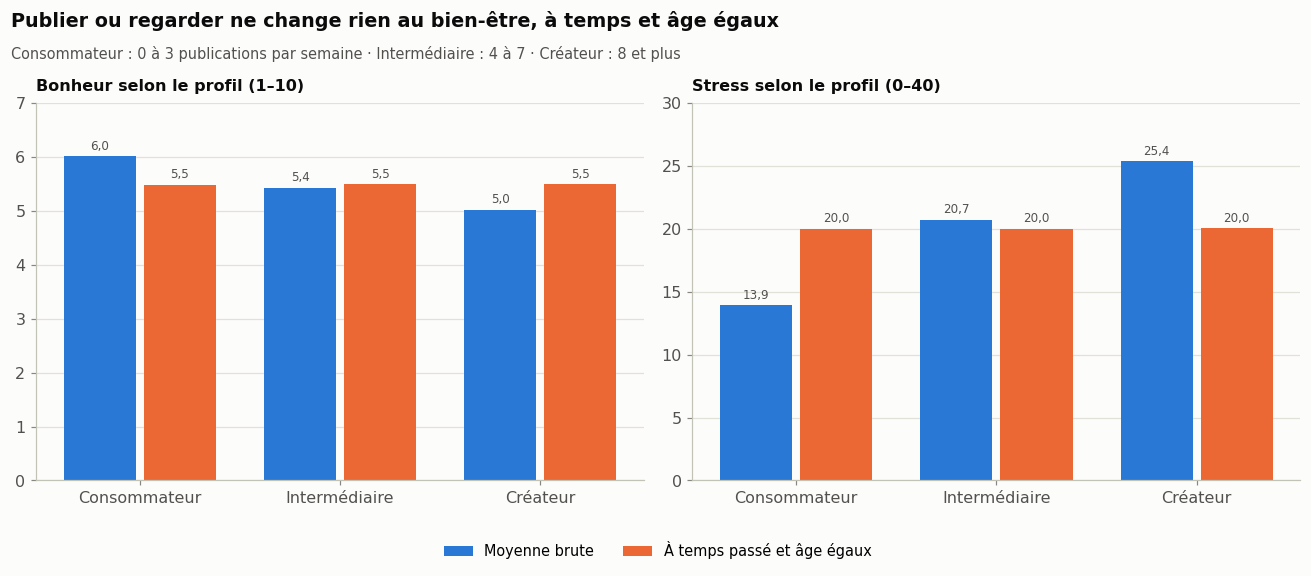

,part des utilisateurs (%),âge moyen,temps par jour (min),bonheur,très heureux (%),très malheureux (%),stress
profil,,,,,,,
Consommateur (0 à 3 publications),"31,6","45,5","117,3","6,0","25,0","15,0","13,9"
Intermédiaire (4 à 7),"37,6","41,1","192,9","5,4","19,4","21,0","20,7"
Créateur (8 et plus),"30,8","29,8","256,8","5,0","15,4","24,4","25,4"


,n,publications_par_semaine
âge,,
13–17 ans,18 913,"10,2"
18–24 ans,26 169,"10,2"
25–34 ans,38 097,"5,0"
35–44 ans,37 914,"4,8"
45–54 ans,37 652,"4,6"
55–65 ans,41 255,"4,5"


In [17]:
PROFILS_PUBLICATION = ["Consommateur (0 à 3 publications)", "Intermédiaire (4 à 7)", "Créateur (8 et plus)"]
df["profil_publication"] = pd.cut(df["posts_created_per_week"], [-1, 3, 7, 1000], labels=PROFILS_PUBLICATION)
df["bonheur_temps_age_egaux"] = a_temps_egal(df, BONHEUR, "tranche_10min_age")
df["stress_temps_age_egaux"] = a_temps_egal(df, STRESS, "tranche_10min_age")
createurs = agreger(df, "profil_publication", age=("age", "mean"), minutes=(TEMPS, "mean"), bonheur=(BONHEUR, "mean"),
                    tres_heureux=("tres_heureux", lambda s: s.mean() * 100), tres_malheureux=("tres_malheureux", lambda s: s.mean() * 100),
                    stress=(STRESS, "mean"), bonheur_egal=("bonheur_temps_age_egaux", "mean"), stress_egal=("stress_temps_age_egaux", "mean"))
createurs.insert(1, "part", createurs["n"] / len(df) * 100)
COURTS_PROFILS = ["Consommateur", "Intermédiaire", "Créateur"]
series = ["Moyenne brute", "À temps passé et âge égaux"]

fig, (ax_g, ax_d) = plt.subplots(1, 2, figsize=(12, 4.2))
barres_groupees(ax_g, pd.DataFrame({series[0]: createurs["bonheur"].to_numpy(), series[1]: createurs["bonheur_egal"].to_numpy()},
                                   index=COURTS_PROFILS), [BLEU, ORANGE])
ax_g.set_ylim(0, 7)
panneau(ax_g, "Bonheur selon le profil (1–10)")
barres_groupees(ax_d, pd.DataFrame({series[0]: createurs["stress"].to_numpy(), series[1]: createurs["stress_egal"].to_numpy()},
                                   index=COURTS_PROFILS), [BLEU, ORANGE])
ax_d.set_ylim(0, 30)
panneau(ax_d, "Stress selon le profil (0–40)")
poignees, etiquettes = ax_g.get_legend_handles_labels()
fig.legend(poignees, etiquettes, loc="upper center", bbox_to_anchor=(0.5, -0.01), ncol=2)
fig.tight_layout()
titrer_figure(fig, "Publier ou regarder ne change rien au bien-être, à temps et âge égaux",
              "Consommateur : 0 à 3 publications par semaine · Intermédiaire : 4 à 7 · Créateur : 8 et plus")
plt.show()
afficher(createurs[["part", "age", "minutes", "bonheur", "tres_heureux", "tres_malheureux", "stress"]].rename(columns={
    "part": "part des utilisateurs (%)", "age": "âge moyen", "minutes": "temps par jour (min)",
    "tres_heureux": "très heureux (%)", "tres_malheureux": "très malheureux (%)"}).rename_axis("profil"))
afficher(agreger(df, "tranche_age", publications_par_semaine=("posts_created_per_week", "mean")).rename_axis("âge"))

- Au premier regard, les **consommateurs** semblent plus heureux (6,0 contre 5,0) et moins stressés que les **créateurs**.
- Mais les créateurs passent **deux fois plus de temps** sur Instagram (257 min contre 117) et sont **beaucoup plus jeunes** (30 ans contre 45) : les moins de 25 ans publient environ 10 fois par semaine, contre 4 à 5 fois au-delà.
- **À temps passé et âge égaux, il ne reste aucune différence** de bonheur ni de stress (barres orange).

**Source :** [Valkenburg, van Driel & Beyens, 2022, New Media & Society](https://journals.sagepub.com/doi/10.1177/14614448211065425) — sur 40 études, la plupart ne confirment pas d'effet différent de l'usage actif (publier) et passif (regarder) sur le bien-être.

> **Ce qu'on retient :** publier ou seulement regarder ne change rien au bien-être : les créateurs semblent moins heureux parce qu'ils sont **plus jeunes et passent plus de temps** sur l'application.

### 4.3 Activité privée ou activité publique ?
- **Activité privée :** les messages privés envoyés. **Activité publique :** les likes et les commentaires. Le fichier ne contient pas de colonne « story privée » ni « partages ».
- La **part d'activité privée** est la part des messages dans l'ensemble des interactions (messages, likes et commentaires), en 5 groupes de taille égale, du plus public (Q1) au plus privé (Q5).
- Le **réglage du compte** (public, amis seulement, privé) est comparé de la même façon.

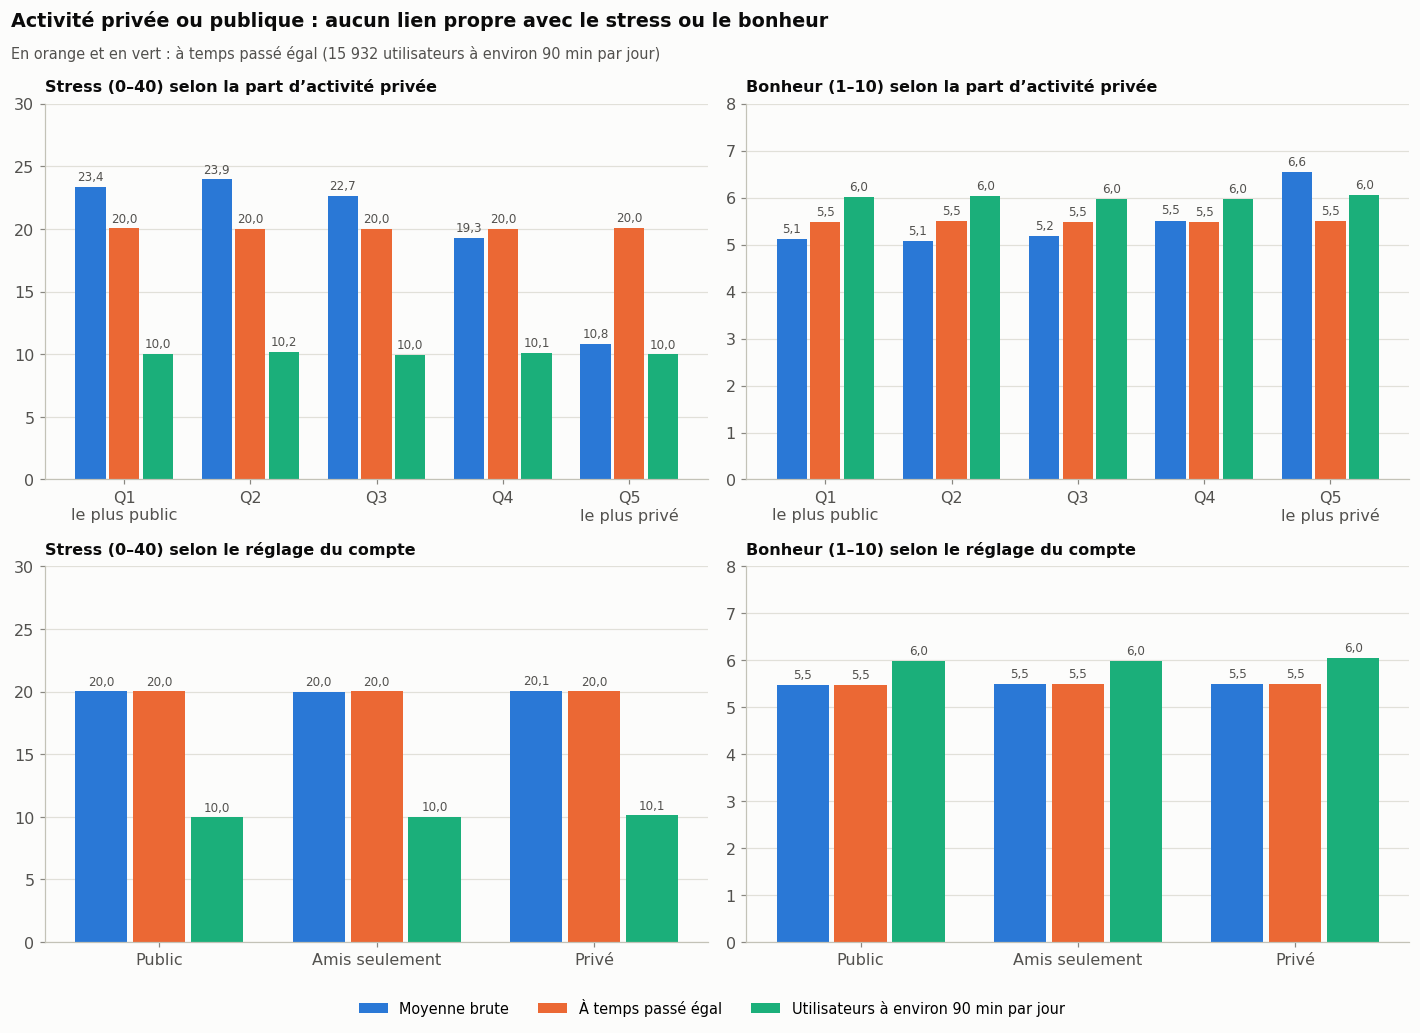

,temps par jour (min),stress,bonheur,stress à temps égal,bonheur à temps égal
groupe,,,,,
Q1 le plus public,"225,7","23,4","5,1","20,0","5,5"
Q2,"232,2","23,9","5,1","20,0","5,5"
Q3,"218,0","22,7","5,2","20,0","5,5"
Q4,"181,0","19,3","5,5","20,0","5,5"
Q5 le plus privé,"86,8","10,8","6,6","20,0","5,5"


In [18]:
QUINTILES = ["Q1 le plus public", "Q2", "Q3", "Q4", "Q5 le plus privé"]
COMPTES = {"Public": "Public", "Friends only": "Amis seulement", "Private": "Privé"}
df["part_privee"] = (df["dms_sent_per_week"] / 7) / (df["dms_sent_per_week"] / 7 + df["likes_given_per_day"] + df["comments_written_per_day"]) * 100
df["quintile_prive"] = pd.qcut(df["part_privee"].rank(method="first"), 5, labels=QUINTILES)
vers_90 = df[(df[TEMPS] >= 75) & (df[TEMPS] <= 105)]
SERIES_PRIVE = ["Moyenne brute", "À temps passé égal", "Utilisateurs à environ 90 min par jour"]


def comparaison(groupe, ordre, colonne, colonne_egale):
    return pd.DataFrame({
        SERIES_PRIVE[0]: df.groupby(groupe, observed=True)[colonne].mean(),
        SERIES_PRIVE[1]: df.groupby(groupe, observed=True)[colonne_egale].mean(),
        SERIES_PRIVE[2]: vers_90.groupby(groupe, observed=True)[colonne].mean(),
    }).reindex(ordre)


fig, axes = plt.subplots(2, 2, figsize=(13, 8.4))
for ligne, (groupe, ordre, noms) in enumerate((("quintile_prive", QUINTILES, ["Q1\nle plus public", "Q2", "Q3", "Q4", "Q5\nle plus privé"]),
                                               ("privacy_setting_level", list(COMPTES), list(COMPTES.values())))):
    for colonne, (variable, limite, nom) in enumerate((("stress", 30, "Stress (0–40)"), ("bonheur", 8, "Bonheur (1–10)"))):
        colonne_brute = STRESS if variable == "stress" else BONHEUR
        table = comparaison(groupe, ordre, colonne_brute, f"{variable}_temps_egal").rename(index=dict(zip(ordre, noms)))
        ax = axes[ligne, colonne]
        barres_groupees(ax, table, [BLEU, ORANGE, AQUA])
        ax.set_ylim(0, limite)
        panneau(ax, f"{nom} selon {'la part d’activité privée' if ligne == 0 else 'le réglage du compte'}")
poignees, etiquettes = axes[0, 0].get_legend_handles_labels()
fig.legend(poignees, etiquettes, loc="upper center", bbox_to_anchor=(0.5, -0.0), ncol=3)
fig.tight_layout()
titrer_figure(fig, "Activité privée ou publique : aucun lien propre avec le stress ou le bonheur",
              f"En orange et en vert : à temps passé égal ({fr(len(vers_90), 0)} utilisateurs à environ 90 min par jour)")
plt.show()

resume = pd.DataFrame({
    "temps par jour (min)": df.groupby("quintile_prive", observed=True)[TEMPS].mean(),
    "stress": df.groupby("quintile_prive", observed=True)[STRESS].mean(),
    "bonheur": df.groupby("quintile_prive", observed=True)[BONHEUR].mean(),
    "stress à temps égal": df.groupby("quintile_prive", observed=True)["stress_temps_egal"].mean(),
    "bonheur à temps égal": df.groupby("quintile_prive", observed=True)["bonheur_temps_egal"].mean(),
}).reindex(QUINTILES)
afficher(resume.rename_axis("groupe"))

- En moyenne brute, les utilisateurs à l'activité **la plus privée** (Q5) semblent deux fois moins stressés et plus heureux. Mais ils passent **2,5 fois moins de temps** sur Instagram (87 min contre 226) : ils envoient surtout des messages, et likent ou commentent peu.
- **À temps passé égal, les cinq groupes sont identiques** (stress de 20,0, bonheur de 5,5). Chez les utilisateurs qui passent environ 90 min par jour, le stress est de 10 et le bonheur de 6,0 dans tous les groupes.
- Le **réglage du compte** ne change rien : comptes publics, « amis seulement » et privés ont le même stress, le même bonheur et le même temps passé.

> **Ce qu'on retient :** le caractère privé ou public de l'activité **n'est pas lié au bien-être**. L'écart apparent vient du temps passé.

### 4.4 Utilisateurs « réflexe » ou « immersion » ?
- **Profil réflexe :** beaucoup de connexions courtes, soit plus de sessions par jour que la médiane (9) **et** des sessions plus courtes que la médiane (20,4 min).
- **Profil immersion :** peu de connexions mais longues, soit moins de sessions par jour que la médiane **et** des sessions plus longues que la médiane.

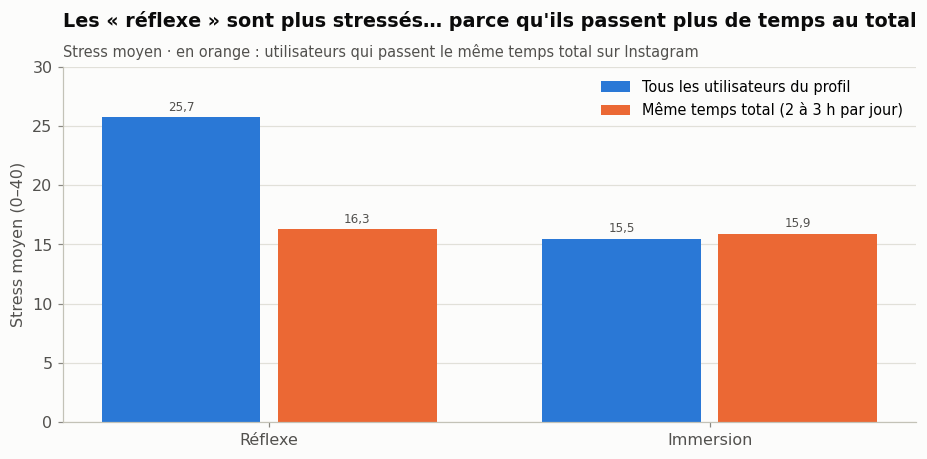

,utilisateurs,sessions par jour,durée d'une session (min),temps total (min par jour),stress (0–40),bonheur (1–10)
profil,,,,,,
Réflexe,59 974,"19,3","13,6","250,2","25,7","4,9"
Immersion,61 543,"4,9","28,8","140,3","15,5","5,8"


Écart de stress brut : +66 % · à temps total égal : 16,3 contre 15,9


In [19]:
mediane_sessions, mediane_duree = df["sessions_per_day"].median(), df["average_session_length_minutes"].median()
reflexe = (df["sessions_per_day"] > mediane_sessions) & (df["average_session_length_minutes"] < mediane_duree)
immersion = (df["sessions_per_day"] < mediane_sessions) & (df["average_session_length_minutes"] > mediane_duree)
df["profil_connexion"] = np.select([reflexe, immersion], ["Réflexe", "Immersion"], default="Autre")
profils_cx = df[df["profil_connexion"] != "Autre"]
connexion = agreger(profils_cx, "profil_connexion", sessions=("sessions_per_day", "mean"), duree=("average_session_length_minutes", "mean"),
                    minutes=(TEMPS, "mean"), stress=(STRESS, "mean"), bonheur=(BONHEUR, "mean")).reindex(["Réflexe", "Immersion"])
meme_temps = profils_cx[(profils_cx[TEMPS] >= 120) & (profils_cx[TEMPS] < 180)]
connexion_meme = agreger(meme_temps, "profil_connexion", minutes=(TEMPS, "mean"), stress=(STRESS, "mean")).reindex(["Réflexe", "Immersion"])

fig, ax = plt.subplots(figsize=(10, 4.2))
barres_groupees(ax, pd.DataFrame({"Tous les utilisateurs du profil": connexion["stress"].to_numpy(),
                                  "Même temps total (2 à 3 h par jour)": connexion_meme["stress"].to_numpy()},
                                 index=["Réflexe", "Immersion"]), [BLEU, ORANGE])
ax.set_ylim(0, 30)
ax.set_ylabel("Stress moyen (0–40)")
ax.legend(loc="upper right")
titrer(ax, "Les « réflexe » sont plus stressés… parce qu'ils passent plus de temps au total",
       "Stress moyen · en orange : utilisateurs qui passent le même temps total sur Instagram")
plt.show()
afficher(connexion.rename(columns={"n": "utilisateurs", "sessions": "sessions par jour", "duree": "durée d'une session (min)",
                                   "minutes": "temps total (min par jour)", "stress": "stress (0–40)", "bonheur": "bonheur (1–10)"}).rename_axis("profil"))
print(f"Écart de stress brut : +{fr((connexion.loc['Réflexe', 'stress'] / connexion.loc['Immersion', 'stress'] - 1) * 100, 0)} % · "
      f"à temps total égal : {fr(connexion_meme.loc['Réflexe', 'stress'])} contre {fr(connexion_meme.loc['Immersion', 'stress'])}")

- Les utilisateurs « réflexe » sont **nettement plus stressés** que les « immersion » (25,7 contre 15,5, soit +66 %).
- Mais ils passent aussi **beaucoup plus de temps au total** sur Instagram (250 min contre 140 par jour), car le temps total est égal aux sessions multipliées par leur durée.
- **À temps total égal (2 à 3 h par jour), l'écart disparaît** : 16,3 contre 15,9. La durée des sessions n'a donc pas de lien propre avec le stress.

**Conclusion pour les équipes produit :** ouvrir Instagram très souvent va avec plus de stress **parce que cela fait plus de temps au total**. Un rappel doit compter **le temps cumulé de la journée**, pas seulement la durée d'une session.

> **Ce qu'on retient :** ce n'est pas la façon de se connecter qui compte, c'est **le temps total** passé chaque jour.

---
## 5. Stress et bonheur

### Le stress lié à l'usage s'accompagne-t-il d'une baisse de bonheur ?

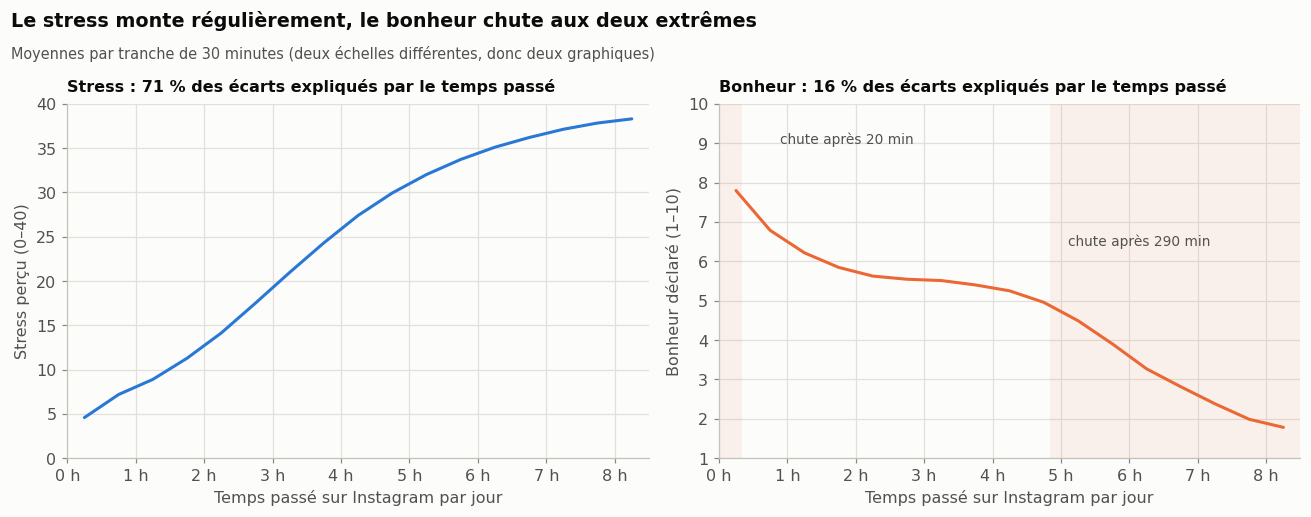

In [20]:
fig, (ax_g, ax_d) = plt.subplots(1, 2, figsize=(12, 4.2))
ax_g.plot(x30, t30["stress"], color=BLEU)
ax_g.set_ylim(0, 40)
ax_g.set_ylabel("Stress perçu (0–40)")
panneau(ax_g, f"Stress : {fr(r2_stress * 100, 0)} % des écarts expliqués par le temps passé")
ax_d.axvspan(0, 20 / 60, color=to_rgba(ORANGE, 0.08), linewidth=0)
ax_d.axvspan(290 / 60, 8.5, color=to_rgba(ORANGE, 0.08), linewidth=0)
ax_d.plot(x30, t30["bonheur"], color=ORANGE)
ax_d.text(0.9, 9.0, "chute après 20 min", fontsize=9, color=INK2)
ax_d.text(5.1, 6.4, "chute après 290 min", fontsize=9, color=INK2)
ax_d.set_ylim(1, 10)
ax_d.set_ylabel("Bonheur déclaré (1–10)")
panneau(ax_d, f"Bonheur : {fr(r2_bonheur * 100, 0)} % des écarts expliqués par le temps passé")
for ax in (ax_g, ax_d):
    ax.set_xlim(0, 8.5)
    ax.xaxis.set_major_formatter(FORMAT_HEURES)
    ax.set_xlabel("Temps passé sur Instagram par jour")
fig.tight_layout()
titrer_figure(fig, "Le stress monte régulièrement, le bonheur chute aux deux extrêmes",
              "Moyennes par tranche de 30 minutes (deux échelles différentes, donc deux graphiques)")
plt.show()

- Le **stress** monte **régulièrement** avec le temps passé.
- Le **bonheur** baisse surtout **aux deux extrêmes** (zones orangées) : très vite après les premières minutes, puis au-delà d'environ 4 h 50 par jour. Entre les deux, il change peu.
- Le temps passé explique **71 %** des écarts de stress, mais seulement **16 %** des écarts de bonheur.

**Conclusion pour les équipes produit :** il faut **suivre le stress et le bonheur séparément** : un utilisateur peut être très stressé et très heureux à la fois. Le lien principal d'Instagram est avec **le stress**.

**Source :** [le modèle « dual continua » de Keyes (Frontiers in Psychology, 2022)](https://www.frontiersin.org/articles/10.3389/fpsyg.2022.885278/full) — la santé mentale positive et la détresse sont deux dimensions distinctes.

> **Ce qu'on retient :** le stress lié à l'usage s'accompagne d'une baisse de bonheur, mais **beaucoup plus faible et concentrée aux extrêmes**. Stress et bonheur sont deux indicateurs différents.

---
## 6. La segmentation

**Deux informations suffisent** : le **segment de temps passé** (S1 à S6) et le **groupe d'âge**. Toutes deux sont connues pour **tous** les utilisateurs, et aucune n'est une donnée de santé.

### 6.1 Pourquoi cette méthode ?
La consigne propose deux voies : **prédire un indicateur de bien-être** à partir de l'usage, ou **regrouper automatiquement** les utilisateurs (*clustering*). Nous avons choisi la première, sous une forme simple : des **segments par paliers** de temps passé, croisés avec l'âge.
- **Un regroupement automatique retrouverait surtout le temps passé** : les compteurs d'activité en sont presque des copies (partie 2.2), et les habitudes d'utilisation n'ajoutent rien à temps égal (partie 4).
- **Ses groupes sont difficiles à expliquer** et peuvent changer d'une exécution à l'autre.
- **Nos segments sont construits pour séparer le stress et le bonheur**, lisibles (« S4 Soutenu, 55–65 ans »), applicables à tous, sans donnée de santé, et calculés en une seule passe sur les 200 000 utilisateurs.

### 6.2 La carte des segments

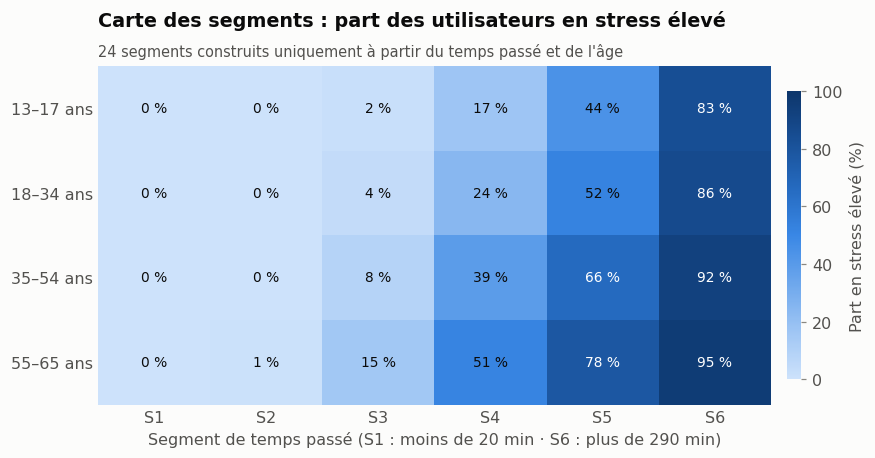

n stress part_stress_eleve
âge       segment                                             
13–17 ans S1 Très occasionnel     549    3,0               0,0
          S2 Occasionnel        1 853    5,6               0,0
          S3 Modéré             5 085   11,1               1,7
          S4 Soutenu            2 946   18,9              16,6
          S5 Intensif           2 841   25,1              43,9
          S6 Très intensif      5 639   32,4              83,2
18–34 ans S1 Très occasionnel   2 768    3,4               0,0
          S2 Occasionnel        7 453    6,3               0,0
          S3 Modéré            18 014   12,8               3,7
          S4 Soutenu           10 281   20,9              24,2
          S5 Intensif           9 420   26,6              51,7
          S6 Très intensif     16 330   32,9              85,9
35–54 ans S1 Très occasionnel   6 054    4,2               0,0
          S2 Occasionnel       11 433    8,0               0,2
          S3 Modéré            22 403   15,4               8,4
          S4 Soutenu           11 785   24,2              38,9
          S5 Intensif          10 359   29,2              66,5
          S6 Très intensif     13 532   34,1              91,8
55–65 ans S1 Très occasionnel   5 141    5,0               0,0
          S2 Occasionnel        7 145    9,6               0,6
          S3 Modéré            12 321   18,0              15,2
          S4 Soutenu            6 372   26,6              51,2
          S5 Intensif           4 997   31,1              78,0
          S6 Très intensif      5 279   34,9              95,3

In [21]:
segments = agreger(df, ["groupe_age", "segment"], stress=(STRESS, "mean"), part_stress_eleve=("stress_eleve", lambda s: s.mean() * 100))
grille = segments["part_stress_eleve"].unstack("segment").reindex(index=GROUPES_AGE, columns=SEGMENTS)
grille_affichee = grille.copy()
grille_affichee.columns = COURTS
fig, ax = plt.subplots(figsize=(9.5, 4))
carte_chaleur(ax, grille_affichee, 0, 100, "Part en stress élevé (%)", suffixe=" %")
ax.set_xlabel("Segment de temps passé (S1 : moins de 20 min · S6 : plus de 290 min)")
titrer(ax, "Carte des segments : part des utilisateurs en stress élevé",
       "24 segments construits uniquement à partir du temps passé et de l'âge")
plt.show()
afficher(segments.rename_axis(["âge", "segment"]))

- Les segments vont de **0 %** à **95 %** d'utilisateurs en stress élevé.
- Dans un même segment de temps, l'âge change fortement le résultat : en S4 (188 à 240 min), **17 %** de stress élevé chez les 13–17 ans contre **51 %** chez les 55–65 ans.

### 6.3 Affecter un nouvel utilisateur à un segment
La fonction n'utilise que l'**âge** et le **temps passé par jour**. Les exemples sont des **utilisateurs fictifs**, pas des lignes du fichier.

In [22]:
def assigner_segment(age, minutes_par_jour):
    """Renvoie le segment d'un utilisateur à partir de son âge et de son temps quotidien sur Instagram."""
    if not 13 <= age <= 65:
        raise ValueError("L'âge doit être compris entre 13 et 65 ans (plage couverte par les données).")
    groupe = pd.cut([age], BORNES_GROUPES_AGE, right=False, labels=GROUPES_AGE)[0]
    segment = pd.cut([minutes_par_jour], BORNES_SEGMENTS, right=False, labels=SEGMENTS)[0]
    profil = segments.loc[(groupe, segment)]
    return {"segment": f"{segment} · {groupe}",
            "part en stress élevé dans le segment (%)": float(profil["part_stress_eleve"]),
            "mineur": age < 18}


exemples = [(16, 250), (30, 250), (60, 250), (60, 90)]  # (âge, minutes par jour), utilisateurs fictifs
afficher(pd.DataFrame([{"âge": a, "minutes par jour": m, **assigner_segment(a, m)} for a, m in exemples]))

,âge,minutes par jour,segment,part en stress élevé dans le segment (%),mineur
0,16,250,S5 Intensif · 13–17 ans,"43,9",oui
1,30,250,S5 Intensif · 18–34 ans,"51,7",non
2,60,250,S5 Intensif · 55–65 ans,"78,0",non
3,60,90,S3 Modéré · 55–65 ans,"15,2",non


### 6.4 Nos critères d'une bonne segmentation
Personne ne nous a dit ce qu'est une bonne segmentation : nous fixons nos propres critères, tous **vérifiables sur les données**.

In [23]:
moitie = np.where(df["user_id"] % 2 == 0, "A", "B")
stabilite = (df.assign(moitie=moitie).groupby(["moitie", "groupe_age", "segment"], observed=True)["stress_eleve"]
             .mean().mul(100).unstack("moitie"))
ecarts_age = grille.max() - grille.min()
criteres = pd.DataFrame([
    ("1. Distingue bien le bien-être", "part en stress élevé, du segment le plus bas au plus haut",
     f"de {fr(grille.min().min(), 0)} % à {fr(grille.max().max(), 0)} %"),
    ("2. Apporte plus que le temps seul", "plus grand écart entre groupes d'âge dans un même segment de temps",
     f"{fr(ecarts_age.max(), 0)} points ({ecarts_age.idxmax()})"),
    ("3. S'applique à tout utilisateur", "valeurs manquantes dans l'âge et le temps passé", str(int(df[["age", TEMPS]].isna().sum().sum()))),
    ("4. Est stable", "plus grand écart entre deux moitiés du fichier", f"{fr((stabilite['A'] - stabilite['B']).abs().max(), 1)} points"),
    ("5. N'isole personne", "plus petit segment", f"{fr(df.groupby(['groupe_age', 'segment'], observed=True).size().min(), 0)} utilisateurs"),
    ("6. Aucune donnée de santé", "variables utilisées", "âge et temps passé par jour"),
], columns=["critère", "mesure", "résultat"]).set_index("critère")
display(criteres)

,mesure,résultat
critère,,
1. Distingue bien le bien-être,"part en stress élevé, du segment le plus bas a...",de 0 % à 95 %
2. Apporte plus que le temps seul,plus grand écart entre groupes d'âge dans un m...,35 points (S4 Soutenu)
3. S'applique à tout utilisateur,valeurs manquantes dans l'âge et le temps passé,0
4. Est stable,plus grand écart entre deux moitiés du fichier,"1,7 points"
5. N'isole personne,plus petit segment,549 utilisateurs
6. Aucune donnée de santé,variables utilisées,âge et temps passé par jour


> **Ce qu'on retient :** les six critères sont atteints : la segmentation est discriminante, utile au-delà du temps passé, applicable à tous, stable, sans risque d'isoler quelqu'un et sans donnée de santé.

### 6.5 Quatre profils de bien-être selon le segment
On croise le stress (élevé à partir de 27) et le bonheur (élevé à partir de 7).

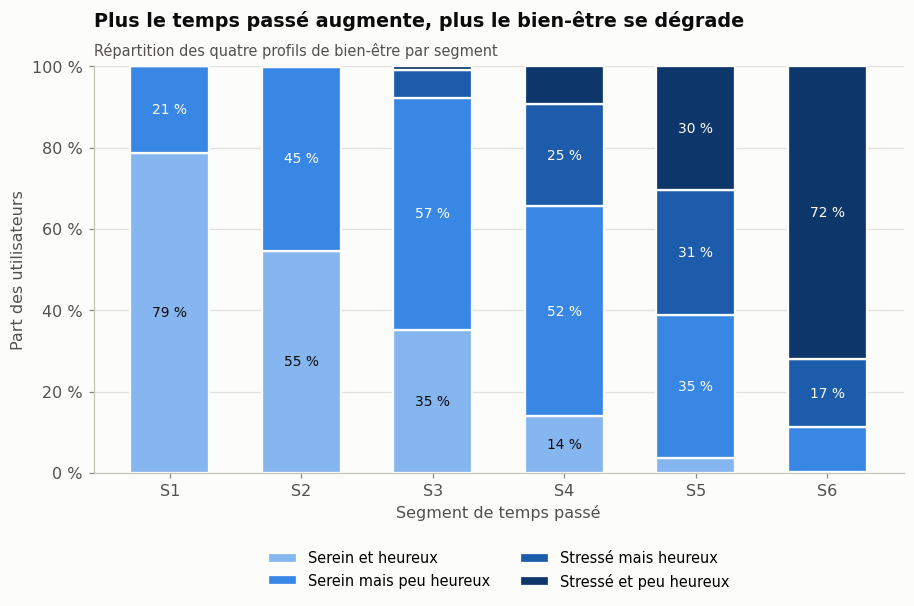

profil,Serein et heureux,Serein mais peu heureux,Stressé mais heureux,Stressé et peu heureux
segment,,,,
S1 Très occasionnel,"78,7","21,3","0,0","0,0"
S2 Occasionnel,"54,6","45,1","0,2","0,0"
S3 Modéré,"35,2","57,0","6,9","0,9"
S4 Soutenu,"14,0","51,6","25,1","9,4"
S5 Intensif,"3,7","35,1","30,8","30,4"
S6 Très intensif,"0,3","11,0","16,7","72,1"


In [24]:
PROFILS = ["Serein et heureux", "Serein mais peu heureux", "Stressé mais heureux", "Stressé et peu heureux"]
profil = np.select([~df["stress_eleve"] & (df[BONHEUR] >= 7), ~df["stress_eleve"] & (df[BONHEUR] < 7),
                    df["stress_eleve"] & (df[BONHEUR] >= 7)], PROFILS[:3], default=PROFILS[3])
parts = pd.crosstab(df["segment"], profil, normalize="index").mul(100)[PROFILS]
fig, ax = plt.subplots(figsize=(9.5, 4.8))
positions = np.arange(len(parts))
base = np.zeros(len(parts))
for couleur, nom in zip(RAMPE_4, PROFILS):
    ax.bar(positions, parts[nom], bottom=base, width=0.6, color=couleur, edgecolor=SURFACE, linewidth=1.5, label=nom)
    for p, b, v in zip(positions, base, parts[nom]):
        if v >= 12:
            ax.text(p, b + v / 2, f"{fr(v, 0)} %", ha="center", va="center", fontsize=9, color=INK if couleur == RAMPE_4[0] else "white")
    base += parts[nom].to_numpy()
ax.set_xticks(positions, COURTS)
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(FORMAT_POURCENT)
ax.grid(axis="x", visible=False)
ax.set_xlabel("Segment de temps passé")
ax.set_ylabel("Part des utilisateurs")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)
titrer(ax, "Plus le temps passé augmente, plus le bien-être se dégrade", "Répartition des quatre profils de bien-être par segment")
plt.show()
afficher(parts.rename_axis(index="segment", columns="profil"))

- En S1, près de **quatre utilisateurs sur cinq** sont sereins et heureux.
- En S6, près des **trois quarts** sont stressés et peu heureux.
- Entre les deux, on passe d'abord par « serein mais peu heureux », puis par « stressé mais heureux ».

**Conclusion pour les équipes produit :** ces profils décrivent **le parcours du bien-être selon la dose d'usage**. Ils restent une lecture des résultats agrégés : **on ne les attribue pas à un utilisateur**, puisqu'ils reposent sur des données de santé du panel.

> **Ce qu'on retient :** plus la dose d'usage augmente, plus les utilisateurs glissent d'un profil serein et heureux vers un profil stressé et peu heureux.

---
## 7. Protection des données

La consigne nous demande de prendre position, pour les utilisateurs de l'Union européenne et du Royaume-Uni, y compris les moins de 18 ans, sur deux questions.

### 7.1 Sur quelles variables les segments peuvent-ils reposer pour du ciblage ?
**Uniquement le temps passé par jour et l'âge.**
- Ce sont des données qu'Instagram détient **pour tous ses utilisateurs**, et ce ne sont **pas des données de santé**.
- **Les variables de santé et de bien-être sont exclues** (stress, bonheur, sommeil, IMC, tension, tabac, alcool, alimentation, sport) : ce sont des données sensibles au sens de l'article 9 du RGPD ([CNIL](https://www.cnil.fr/fr/definition/donnee-sensible)), données seulement pour l'étude bien-être.
- **Les autres variables de profil sont exclues aussi** (genre, revenu, emploi, couple, enfants, pays) : elles n'apportent rien, et le RGPD demande de ne traiter que les données nécessaires.

### 7.2 Placer un utilisateur dans un segment peut-il révéler quelque chose sur sa santé ?

In [25]:
groupe_max, segment_max = segments["part_stress_eleve"].idxmax()
revelateurs = segments[segments["part_stress_eleve"] >= 80]
print(f"Segment le plus révélateur : {segment_max} · {groupe_max}, avec {fr(segments['part_stress_eleve'].max(), 0)} % de ses membres en stress élevé")
print(f"{len(revelateurs)} segments sur {len(segments)} comptent au moins 80 % d'utilisateurs en stress élevé "
      f"({fr(revelateurs['n'].sum() / len(df) * 100, 0)} % des utilisateurs).")

Segment le plus révélateur : S6 Très intensif · 55–65 ans, avec 95 % de ses membres en stress élevé
4 segments sur 24 comptent au moins 80 % d'utilisateurs en stress élevé (20 % des utilisateurs).


**Oui.** Même construits sans donnée de santé, certains segments laissent deviner un état de stress avec une forte probabilité. Une donnée qui révèle indirectement un état de santé doit être traitée comme une donnée de santé. D'où trois conditions :
- **nommer les segments par l'usage** (« S6 Très intensif, 55–65 ans »), jamais par le stress attendu ;
- **ne stocker aucun score de stress** par utilisateur ;
- **réserver les segments aux outils de protection** (rappels de temps, mode sommeil), sans publicité.

### 7.3 Les mineurs
- **Royaume-Uni :** le code de conception adapté à l'âge de l'ICO demande que **le profilage des enfants soit désactivé par défaut**, sauf raison impérieuse dans leur intérêt ([résumé par RPC](https://www.rpclegal.com/snapshots/data-protection/ico-age-appropriate-design-code-for-information-society-services/)).
- **Union européenne :** le DSA (article 28) **interdit les publicités fondées sur le profilage** d'un utilisateur dont la plateforme sait qu'il est mineur ([EUR-Lex](https://eur-lex.europa.eu/eli/reg/2022/2065/oj)).

### 7.4 Les mesures que nous appliquons et recommandons
- **Seuil de 100 utilisateurs :** aucune ligne individuelle ni aucun groupe de moins de 100 personnes n'est affiché (vérification ci-dessous).
- **Données brutes jamais publiées :** le dossier `data/` est exclu du dépôt du projet par le fichier `.gitignore` ; seule la copie qui sert à l'application en ligne se trouve dans un dépôt privé.
- **Une section « Limites et protection des données »** dans le notebook, l'application et le README.
- **Interdiction écrite** d'utiliser les segments pour la publicité ou de les transmettre aux annonceurs.
- **Informer les utilisateurs** du classement en segments, dans la politique de confidentialité.
- **Inscrire le traitement au registre des traitements**, avec sa finalité, les données utilisées et la durée de conservation.

In [26]:
afficher(pd.Series({
    "segments de temps (S1 à S6)": df.groupby("segment", observed=True).size().min(),
    "segments âge × temps": df.groupby(["groupe_age", "segment"], observed=True).size().min(),
    "âge × temps (tranches fines)": df.groupby(["tranche_age", "segment"], observed=True).size().min(),
}, name="plus petit groupe (utilisateurs)").to_frame(), 0)

,plus petit groupe (utilisateurs)
segments de temps (S1 à S6),14 512
segments âge × temps,549
âge × temps (tranches fines),549


---
## 8. Limites

### 8.1 Pas de cause à effet
Tous nos liens sont des **corrélations**. On ne peut pas dire qu'Instagram *cause* le stress : les personnes stressées pourraient aussi passer plus de temps sur l'application. Seules des expériences, où l'on fait varier le temps passé, peuvent tester une cause.

### 8.2 Un panel de volontaires
Le stress et le bonheur ne sont mesurés que chez les **volontaires** de l'étude bien-être. Ils ne ressemblent pas forcément à l'ensemble des utilisateurs.

### 8.3 Une réplique synthétique
- **Le lien entre temps passé et stress est très fort** : 71 % des écarts expliqués, contre 0,4 % au maximum dans les études réelles ([Orben & Przybylski, 2019](https://www.oii.ox.ac.uk/technology-use-explains-at-most-0-4-of-adolescent-wellbeing/)).
- **Des effets connus sont absents** : le sommeil et le nombre de pas n'ont aucun lien ici, alors que nos sources les associent au bien-être (partie 1).
- **Les deux versions du fichier (« usage » et « users ») sont presque identiques**, et le nettoyage de l'une n'est pas documenté (partie 0).
- **27 % des lignes ont au moins une incohérence métier** : elles sont signalées, et les résultats ne changent pas sans elles (partie 0).
- **Un lien caché, très probablement artificiel, entre stress et bonheur** :

Corrélation stress ↔ bonheur sur tous les utilisateurs : 0,00
Corrélation stress ↔ bonheur à temps passé égal : 0,60


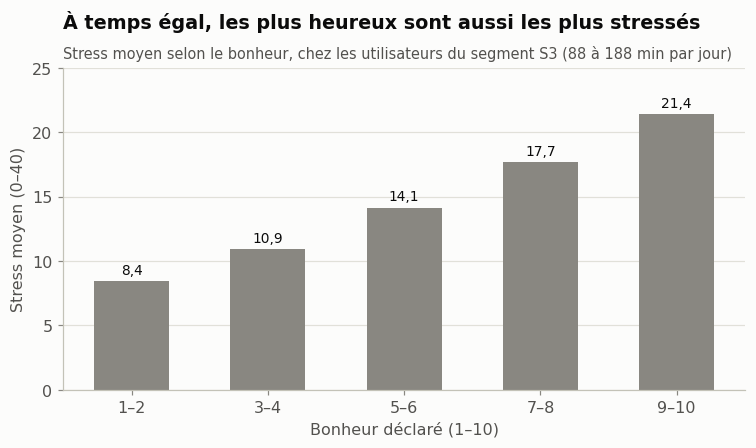

In [27]:
residu = lambda c: df[c] - df.groupby("tranche_10min")[c].transform("mean")  # noqa: E731
print(f"Corrélation stress ↔ bonheur sur tous les utilisateurs : {fr(df[STRESS].corr(df[BONHEUR]), 2)}")
print(f"Corrélation stress ↔ bonheur à temps passé égal : {fr(np.corrcoef(residu(STRESS), residu(BONHEUR))[0, 1], 2)}")
niveau_bonheur = pd.cut(df[BONHEUR], [0, 2, 4, 6, 8, 10], labels=["1–2", "3–4", "5–6", "7–8", "9–10"])
lien_cache = agreger(df[df["segment"] == "S3 Modéré"].assign(niveau_bonheur=niveau_bonheur), "niveau_bonheur", stress_moyen=(STRESS, "mean"))
fig, ax = plt.subplots(figsize=(8, 3.8))
barres(ax, lien_cache["stress_moyen"], lien_cache.index, couleur=MUTED)
ax.set_ylim(0, 25)
ax.set_xlabel("Bonheur déclaré (1–10)")
ax.set_ylabel("Stress moyen (0–40)")
titrer(ax, "À temps égal, les plus heureux sont aussi les plus stressés",
       "Stress moyen selon le bonheur, chez les utilisateurs du segment S3 (88 à 188 min par jour)")
plt.show()

- Sur l'ensemble des utilisateurs, stress et bonheur **ne sont pas liés**. Mais **à temps passé égal**, ils sont **fortement liés, dans le même sens**.
- **C'est très probablement un effet de la génération des données** : dans la réalité, on s'attend plutôt à ce que les personnes stressées soient moins heureuses. Ce lien ne sert pas à la segmentation.

### 8.4 D'autres points de prudence
- **Le seuil de stress élevé (27)** est une convention de lecture de l'échelle PSS-10, pas un seuil de diagnostic.
- **Les colonnes « story privée » et « partages » n'existent pas** : l'activité privée n'est mesurée que par les messages (partie 4.3).

> **Ce qu'on retient :** nos résultats décrivent **des tendances fortes dans une réplique synthétique**. Ils indiquent où regarder, mais doivent être **confirmés sur de vraies données**, et ne permettent jamais de conclure à une cause.

---
## 9. Conclusion et recommandations

### Le lien entre l'usage d'Instagram et le bien-être
- **Le temps passé chaque jour est le facteur central.** Il explique **71 %** des écarts de stress (environ +5,4 points par heure) et **16 %** des écarts de bonheur, qui chute surtout aux deux extrêmes. Les plus heureux passent deux fois moins de temps sur l'application que les moins heureux.
- **L'âge change ce lien.** Les plus jeunes passent plus de temps sur Instagram, mais à temps égal, les plus âgés sont plus stressés (+1,2 point par tranche de 10 ans).
- **Les habitudes d'utilisation n'ajoutent rien au temps passé** : intensité des actions, création ou consommation de contenu, activité privée ou publique, connexions « réflexe » ou « immersion ». Toutes leurs différences disparaissent à temps égal.
- **Le sommeil, l'activité physique et le pays ne sont pas liés** à l'usage dans notre panel.
- **Stress et bonheur sont deux indicateurs distincts**, à suivre séparément.

### Une segmentation utilisable par les équipes produit
- **Six segments de temps passé (S1 à S6) croisés avec quatre groupes d'âge** : deux informations connues pour tous les utilisateurs, sans donnée de santé.
- La carte des segments donne directement **les groupes à accompagner en priorité**, et un nouvel utilisateur peut y être placé avec la fonction `assigner_segment` (partie 6.3).
- **Les limites** (partie 8) : des corrélations et non des causes, un panel de volontaires, et une réplique synthétique.

### Recommandations
1. **Un rappel de temps quotidien cumulé, avec un seuil selon l'âge.** Dès le segment S3 (88 à 188 min par jour), 15 % des 55–65 ans sont en stress élevé, contre 2 % des 13–17 ans, qui ne dépassent 15 % qu'en S4. Nous recommandons un rappel **à l'entrée de S3 (environ 1 h 30 par jour) pour les 55–65 ans** et **à l'entrée de S4 (environ 3 h) pour les autres**, **activé par défaut pour les mineurs**. Le rappel doit compter le temps **de toute la journée**, pas celui d'une seule session (partie 4.4).
2. **Faire du temps quotidien passé l'indicateur de suivi numéro un**, par segment, dans les tableaux de bord produit, plutôt que les compteurs d'activité ou le score d'engagement, qui n'apportent rien de plus. Dans les études bien-être, **suivre le stress et le bonheur séparément**.
3. **Réserver les segments aux outils de protection** (rappels, mode sommeil) : jamais de publicité, des segments nommés par l'usage et non par le stress, et une analyse d'impact sur la protection des données avant tout déploiement.

> **En une phrase :** plus on passe de temps sur Instagram, plus on est stressé, et ce lien est plus fort chez les plus âgés ; une segmentation simple par temps passé et âge permet aux équipes produit de cibler leurs outils de protection, sans utiliser de données de santé.

---
## Sources
**Définitions**
- OMS : [constitution de l'Organisation mondiale de la santé](https://www.who.int/fr/about/governance/constitution)
- Santé publique France : [« On a toutes et tous une santé mentale » (sante.fr)](https://www.sante.fr/toutes-et-tous-une-sante-mentale)
- World Happiness Report : [questions fréquentes, échelle de Cantril](https://www.worldhappiness.report/faq/)
- Échelle PSS-10 : [guide de cotation (NovoPsych)](https://novopsych.com.au/wp-content/uploads/2022/02/pss-10-report-PDF.pdf)

**Temps passé, âge et bien-être**
- Riehm et al., 2019, *JAMA Psychiatry* : [présentation par Johns Hopkins](https://hub.jhu.edu/2019/09/11/social-media-teen-mental-health/)
- Liu et al., 2022, méta-analyse dose–effet : [texte intégral (PMC)](https://pmc.ncbi.nlm.nih.gov/articles/PMC9103874/)
- Orben & Przybylski, 2019, *Nature Human Behaviour* : [Oxford Internet Institute](https://www.oii.ox.ac.uk/technology-use-explains-at-most-0-4-of-adolescent-wellbeing/)
- Assemblée nationale, question écrite citant le rapport « Enfants et écrans » (2024) : [PDF](https://www.assemblee-nationale.fr/dyn/16/questions/QANR5L16QE18298.pdf)
- Valkenburg, van Driel & Beyens, 2022, *New Media & Society* : [article](https://journals.sagepub.com/doi/10.1177/14614448211065425)
- Modèle de Keyes : [Frontiers in Psychology, 2022](https://www.frontiersin.org/articles/10.3389/fpsyg.2022.885278/full)

**Mode de vie**
- info.gouv.fr, 2025 : [le sommeil et la santé mentale](https://www.info.gouv.fr/actualite/sante-mentale-pourquoi-le-sommeil-joue-un-role-cle)
- Ameli : [activité physique et bien-être](https://www.ameli.fr/assure/sante/themes/activite-physique-sante/sport-et-activite-physique-un-atout-pour-le-bien-etre)

**Protection des données**
- [CNIL, données sensibles](https://www.cnil.fr/fr/definition/donnee-sensible) · [DSA (EUR-Lex)](https://eur-lex.europa.eu/eli/reg/2022/2065/oj) · [code de l'ICO (résumé par RPC)](https://www.rpclegal.com/snapshots/data-protection/ico-age-appropriate-design-code-for-information-society-services/)